#### trains a Self-Organizing Map on ~30,000 dwarf galaxies using 7 photometric color features (brightness measurements at different wavelengths) 
#### The SOM maps galaxies with similar photometric colors onto a 51×51 grid, where nearby cells contain galaxies that resemble each other
#### Input: NSA_dwarfs_updated.csv — NASA-Sloan Atlas dwarf galaxy catalog


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import astropy.io.fits as fits
from mpl_toolkits.axes_grid1 import make_axes_locatable
import matplotlib as mpl
import scipy.interpolate
import sompy


def abmag(flux): 
    '''to convert flux to AB magnitude'''
    u=np.zeros_like(flux)
    for i in range(len(flux)):
        if flux[i] <= 0 or np.isnan(flux[i]):
            u[i]=-99.0
        else:
            u[i]=22.5 - 2.5*(np.log10(flux[i]))
    return u


def surakh(m):
    mask = ~(np.isnan(m))
    xx, yy = np.meshgrid(np.arange(np.shape(m)[1]), np.arange(np.shape(m)[0]))
    xym = np.vstack( (np.ravel(xx[mask]), np.ravel(yy[mask])) ).T
    data0 = np.ravel( m[mask] )
    interp0 = scipy.interpolate.NearestNDInterpolator( xym, data0 )
    result0 = interp0(np.ravel(xx), np.ravel(yy)).reshape( xx.shape )
    return result0


zmin = 0
zmax = 1

# Load CSV file into a DataFrame
df = pd.read_csv('NSA_dwarfs_updated.csv')
cor = pd.read_csv('NSA_dwarfs_updated - Coronal_lines.csv')
STB = pd.read_csv('STBtest.csv')
tar = pd.read_csv('Copy of NSA_dwarfs_updated - Sheet3.csv')

# Convert DataFrame to a NumPy array
array = df.to_numpy()[1:]
array[array == 'nan'] = '-99'  # Replace 'nan' with '0'
array[array == '--'] = '-99'
array[array == 'AGN'] = '1'
array[array == 'Seyfert'] = '1'
array[array == 'LINER'] = '1'
array[array == 'TRUE'] = '1'
array[array == 'False'] = '0'
array[array == 'Composite'] = '2'
numeric_array = array.astype(float)

# Convert DataFrame to a NumPy array
coronal = cor.to_numpy()[1:]
coronal[coronal == 'nan'] = '-99'  # Replace 'nan' with '0'
coronal[coronal == '--'] = '-99'
coronal[coronal == 'AGN'] = '1'
coronal[coronal == 'Seyfert'] = '1'
coronal[coronal == 'LINER'] = '1'
coronal[coronal == 'TRUE'] = '1'
coronal[coronal == 'Composite'] = '2'
numeric_coronal = coronal.astype(float)
# Display the resulting NumPy array

# Convert DataFrame to a NumPy array
starb = STB.to_numpy()[1:]
starb[starb == 'nan'] = '-99'  # Replace 'nan' with '0'
starb[starb == '--'] = '-99'
starb[starb == 'AGN'] = '1'
starb[starb == 'Seyfert'] = '1'
starb[starb == 'LINER'] = '1'
starb[starb == 'TRUE'] = '1'
starb[starb == 'False'] = '0'
starb[starb == 'Composite'] = '2'
numeric_starb = starb.astype(float)

target = tar.to_numpy()[1:]
target[target == 'nan'] = '-99'  # Replace 'nan' with '0'
target[target == '--'] = '-99'
target[target == 'AGN'] = '1'
target[target == 'Seyfert'] = '1'
target[target == 'LINER'] = '1'
target[target == 'TRUE'] = '1'
target[target == 'Composite'] = '2'
numeric_TJ1205 = target.astype(float)

print(numeric_starb)


In [2]:
np.shape(numeric_array)
np.shape(numeric_coronal)

(55, 54)

In [3]:
dwarf = numeric_array.T
coronal = numeric_coronal.T
starburst = numeric_starb.T
target = numeric_TJ1205.T

In [4]:
print(np.shape(coronal))

(54, 55)


In [5]:
AGN = dwarf[:, :437]
print(AGN[0][436])

131.365003


In [6]:
#generating both training set and AGN test set
f, n, u, g, r, i, z, w1, w2 = np.array(dwarf[:][13]), np.array(dwarf[:][15]), np.array(dwarf[:][17]), np.array(dwarf[:][19]), np.array(dwarf[:][21]), np.array(dwarf[:][23]), np.array(dwarf[:][25]), np.array(dwarf[:][27]), np.array(dwarf[:][29])
fAGN, nAGN, uAGN, gAGN, rAGN, iAGN, zAGN, w1AGN, w2AGN = np.array(AGN[:][13]), np.array(AGN[:][15]), np.array(AGN[:][17]), np.array(AGN[:][19]), np.array(AGN[:][21]), np.array(AGN[:][23]), np.array(AGN[:][25]), np.array(AGN[:][27]), np.array(AGN[:][29])
fc, nc, uc, gc, rc, ic, zc, w1c, w2c = np.array(coronal[:][15]), np.array(coronal[:][17]), np.array(coronal[:][19]), np.array(coronal[:][21]), np.array(coronal[:][23]), np.array(coronal[:][25]), np.array(coronal[:][27]), np.array(coronal[:][29]), np.array(coronal[:][31])
fst, nst, ust, gst, rst, ist, zst, w1st, w2st = np.array(starburst[:][13]), np.array(starburst[:][15]), np.array(starburst[:][17]), np.array(starburst[:][19]), np.array(starburst[:][21]), np.array(starburst[:][23]), np.array(starburst[:][25]), np.array(starburst[:][27]), np.array(starburst[:][29])
ft, nt, ut, gt, rt, it, zt, w1t, w2t = np.array(target[:][4]), np.array(target[:][5]), np.array(target[:][6]), np.array(target[:][7]), np.array(target[:][8]), np.array(target[:][9]), np.array(target[:][10]), np.array(target[:][11]), np.array(target[:][12])
Halpha, Hbeta, OIII, OII = np.array(dwarf[:][37]), np.array(dwarf[:][39]), np.array(dwarf[:][41]), np.array(dwarf[:][43])
RA, Dec = np.array(dwarf[:][0]), np.array(dwarf[:][1])


mass, redshift = np.array(dwarf[:][4]), np.array(dwarf[:][2])
massAGN, redshiftAGN = np.array(AGN[:][4]), np.array(AGN[:][2])
massc, redshiftc = np.array(coronal[:][4]), np.array(coronal[:][2])

con = (f > 0)&(n > 0)&(u > 0)&(g > 0)&(r > 0)&(i > 0)&(z > 0)&(w1 > 0)&(w2 > 0)&(zmin < redshift)&(redshift < zmax)
conAGN = (fAGN > 0)&(nAGN > 0)&(uAGN > 0)&(gAGN > 0)&(rAGN > 0)&(iAGN > 0)&(zAGN > 0)&(w1AGN > 0)&(w2AGN > 0)&(zmin < redshiftAGN)&(redshiftAGN < zmax)
conc = (fc > 0)&(nc > 0)&(uc > 0)&(gc > 0)&(rc > 0)&(ic > 0)&(zc > 0)&(w1c > 0)&(w2c > 0)&(zmin < redshiftc)&(redshiftc < zmax)
const = (fst > 0)&(nst > 0)&(ust > 0)&(gst > 0)&(rst > 0)&(ist > 0)&(zst > 0)&(w1st > 0)&(w2st > 0)

f_clean, n_clean, u_clean , g_clean, r_clean, i_clean, z_clean, w1_clean, w2_clean = f[con], n[con], u[con], g[con], r[con], i[con], z[con], w1[con], w2[con]
fAGN_clean, nAGN_clean, uAGN_clean , gAGN_clean, rAGN_clean, iAGN_clean, zAGN_clean, w1AGN_clean, w2AGN_clean = fAGN[conAGN], nAGN[conAGN], uAGN[conAGN], gAGN[conAGN], rAGN[conAGN], iAGN[conAGN], zAGN[conAGN], w1AGN[conAGN], w2AGN[conAGN]
fc_clean, nc_clean, uc_clean , gc_clean, rc_clean, ic_clean, zc_clean, w1c_clean, w2c_clean = fc[conc], nc[conc], uc[conc], gc[conc], rc[conc], ic[conc], zc[conc], w1c[conc], w2c[conc]
fst_clean, nst_clean, ust_clean , gst_clean, rst_clean, ist_clean, zst_clean, w1st_clean, w2st_clean = fst[const], nst[const], ust[const], gst[const], rst[const], ist[const], zst[const], w1st[const], w2st[const]
Halphaclean, Hbetaclean, OIIIclean, OIIclean = Halpha[con], Hbeta[con], OIII[con], OII[con]
massclean = mass[con]
redshiftclean = redshift[con]

#with np.errstate(divide='ignore', invalid='ignore'):
 #   Halphabeta = np.where(Hbetaclean == 0, 0, Halphaclean / Hbetaclean)  # Set 0 where Beta = 0

    
massAGNclean = massAGN[conAGN]
redshiftAGNclean = redshiftAGN[conAGN]



#generating colors for training
fn, nu, ug, gr, ri, iz, w12 = abmag(f_clean) - abmag(n_clean), abmag(n_clean) - abmag(u_clean), abmag(u_clean) - abmag(g_clean), abmag(g_clean) - abmag(r_clean), abmag(r_clean) - abmag(i_clean), abmag(i_clean) - abmag(z_clean), w1_clean - w2_clean
fnAGN, nuAGN, ugAGN, grAGN, riAGN, izAGN, w12AGN = abmag(fAGN_clean) - abmag(nAGN_clean), abmag(nAGN_clean) - abmag(uAGN_clean), abmag(uAGN_clean) - abmag(gAGN_clean), abmag(gAGN_clean) - abmag(rAGN_clean), abmag(rAGN_clean) - abmag(iAGN_clean), abmag(iAGN_clean) - abmag(zAGN_clean), w1AGN_clean - w2AGN_clean
fnc, nuc, ugc, grc, ric, izc, w12c = abmag(fc_clean) - abmag(nc_clean), abmag(nc_clean) - abmag(uc_clean), abmag(uc_clean) - abmag(gc_clean), abmag(gc_clean) - abmag(rc_clean), abmag(rc_clean) - abmag(ic_clean), abmag(ic_clean) - abmag(zc_clean), w1c_clean - w2c_clean
fns, nus, ugs, grs, ris, izs, w12s = abmag(fst_clean) - abmag(nst_clean), abmag(nst_clean) - abmag(ust_clean), abmag(ust_clean) - abmag(gst_clean), abmag(gst_clean) - abmag(rst_clean), abmag(rst_clean) - abmag(ist_clean), abmag(ist_clean) - abmag(zst_clean), w1st_clean - w2st_clean
fnt, nut, ugt, grt, rit, izt, w12t = abmag(ft) - abmag(nt), abmag(nt) - abmag(ut), abmag(ut) - abmag(gt), abmag(gt) - abmag(rt), abmag(rt) - abmag(it), abmag(it) - abmag(zt), w1t - w2t


#finalizing the training set
dat = np.array([fn, nu, ug, gr, ri, iz, w12])
data = dat.T

print(OII)
print(np.shape(gr))

[-9999.         -9999.         -9999.         ...    51.48342896
    91.2512207      0.        ]
(30344,)


Text(0, 0.5, 'Count')

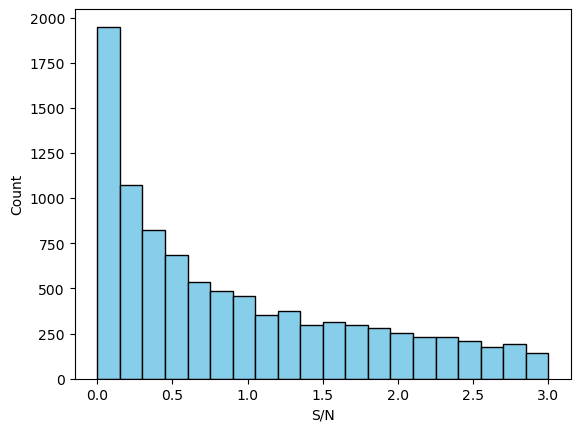

In [9]:
ferr, nerr, uerr, gerr, rerr, ierr, zerr, w1err, w2err  = np.array(dwarf[:][14]), np.array(dwarf[:][16]), np.array(dwarf[:][18]), np.array(dwarf[:][20]), np.array(dwarf[:][22]), np.array(dwarf[:][24]), np.array(dwarf[:][26]), np.array(dwarf[:][28]), np.array(dwarf[:][30])
ferr_clean, nerr_clean, uerr_clean, gerr_clean, rerr_clean, ierr_clean, zerr_clean, w1err_clean, w2err_clean = (ferr[con])**-2, (nerr[con])**-2, (uerr[con])**-2, (gerr[con])**-2, (rerr[con])**-2, (ierr[con])**-2, (zerr[con])**-2, (w1err[con]), (w2err[con])
SN1, SN2, SN3, SN4, SN5, SN6, SN7, SN8, SN9 = f_clean/ferr_clean, n_clean/nerr_clean, u_clean/uerr_clean, g_clean/gerr_clean, r_clean/rerr_clean, i_clean/ierr_clean, z_clean/zerr_clean, w1_clean/w1err_clean, w2_clean/w2err_clean
conn = SN1 > 2.8, SN2 > 2.8, SN3 > 2.8, SN4 > 2.8, SN5 > 2.8, SN6 > 2.8, SN7 > 2.8, SN8 > 2.8, SN9 > 2.8
plt.hist(SN2, bins=20, color='skyblue', edgecolor='black', range=(0, 3))
plt.xlabel("S/N")
plt.ylabel("Count")
#Only 183 targets here have S/N ratio smaller than 3.

Text(0, 0.5, 'Count')

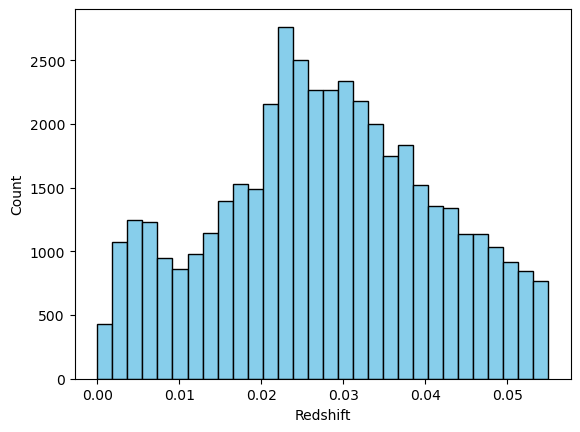

In [10]:
plt.hist(redshift, bins=30, color='skyblue', edgecolor='black', range=(0, max(redshift)))
plt.xlabel("Redshift")
plt.ylabel("Count")

Text(0, 0.5, 'Count')

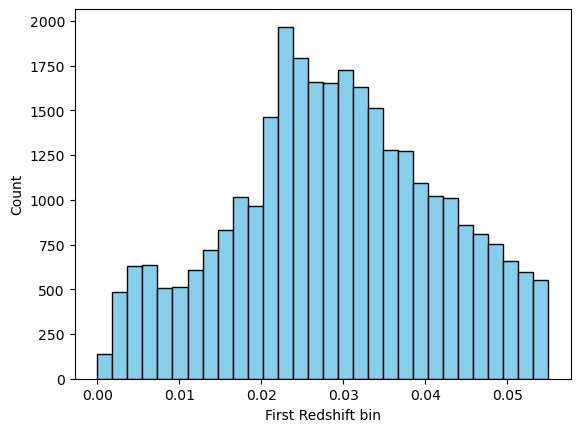

In [11]:
plt.hist(redshiftclean, bins=30, color='skyblue', edgecolor='black', range=(0, max(redshiftclean)))
plt.xlabel("First Redshift bin")
plt.ylabel("Count")

In [12]:
print(np.shape(data))

(30344, 7)


In [13]:
print(np.shape(data))

(30344, 7)


In [14]:
print(max(massclean))

9.203765384


In [15]:
#map size
msz0 = 51
msz1 = 51
sm = sompy.SOMFactory.build(data, mapsize=[msz0,msz1], mapshape='planar', lattice='rect', initialization='pca') 
sm.train(n_job=4, shared_memory = 'no')

 Training...
 pca_linear_initialization took: 0.054000 seconds
 Rough training...
 radius_ini: 7.000000 , radius_final: 1.750000, trainlen: 3

 epoch: 1 ---> elapsed time:  3.099000, quantization error: 1.457755

 epoch: 2 ---> elapsed time:  2.733000, quantization error: 1.304373

 epoch: 3 ---> elapsed time:  2.670000, quantization error: 1.120778

 Finetune training...
 radius_ini: 1.750000 , radius_final: 1.000000, trainlen: 4

 epoch: 1 ---> elapsed time:  2.921000, quantization error: 0.895672

 epoch: 2 ---> elapsed time:  2.882000, quantization error: 0.817402

 epoch: 3 ---> elapsed time:  2.865000, quantization error: 0.766933

 epoch: 4 ---> elapsed time:  2.752000, quantization error: 0.725664

 Final quantization error: 0.686936
 train took: 25.903000 seconds


/var/folders/5z/mxcl46zj3p76_rgxd645pmzr0000gn/T/ipykernel_85598/1961693035.py:31: RuntimeWarning: invalid value encountered in divide
  Halphabeta = np.where(Hbetaclean == 0, 0, Halphaclean / Hbetaclean)
/Users/sogolsanjaripour/anaconda3/lib/python3.10/site-packages/numpy/lib/nanfunctions.py:1215: RuntimeWarning: Mean of empty slice
  return np.nanmean(a, axis, out=out, keepdims=keepdims)


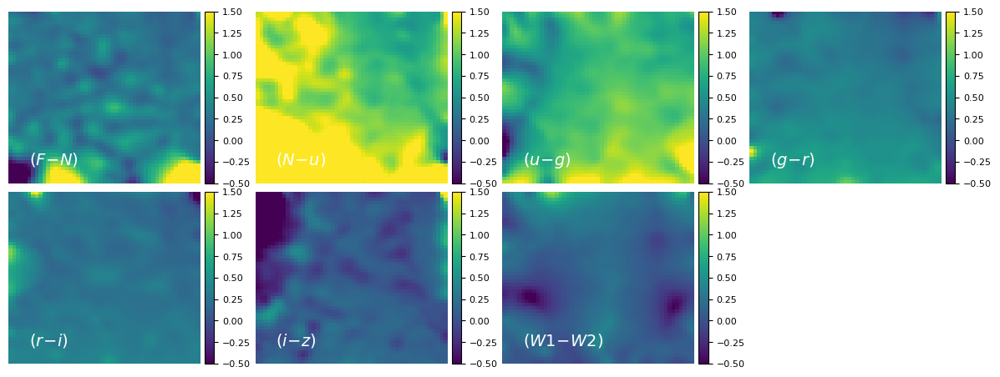

In [16]:
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import numpy as np

# Create the outer grid with 2 rows and 1 column
fig = plt.figure(figsize=(12, 9))
outer_grid = gridspec.GridSpec(2, 1, height_ratios=[1, 1])

# First row: 2x4 grid
inner_grid_2x4 = gridspec.GridSpecFromSubplotSpec(2, 4, subplot_spec=outer_grid[0])

# Second row: 1x2 grid
inner_grid_1x2 = gridspec.GridSpecFromSubplotSpec(1, 2, subplot_spec=outer_grid[1])


colors = [r'$(F\!-\!N)$', r'$(N\!-\!u)$', r'$(u\!-\!g)$', r'$(g\!-\!r)$', r'$(r\!-\!i)$', r'$(i\!-\!z)$', r'$(W1\!-\!W2)$']
codebook = sm._normalizer.denormalize_by(sm.data_raw, sm.codebook.matrix)
for ind in range(7):
    ax = fig.add_subplot(inner_grid_2x4[ind])
    mp = codebook[:, ind].reshape(sm.codebook.mapsize[0], sm.codebook.mapsize[1])
    im = ax.imshow(mp, origin='lower', cmap='viridis', aspect='auto',vmin=-0.5,vmax=1.5)  # Ensure aspect ratio is preserved
    #ax.set_title(colors[ind], fontsize=14, pad=10)  # Adjust title font size and padding
    ax.text(5,5,colors[ind],size=14,color='w')
    ax.tick_params(axis='both', which='major', labelsize=10)  # Adjust tick label font size
    divider = make_axes_locatable(ax)
    cax = divider.append_axes("right", size="5%", pad=0.05)
    cbar = plt.colorbar(im, cax=cax)
    cbar.ax.tick_params(labelsize=8)  # Adjust colorbar tick label font size
    ax.axis('off')

Halphabeta = np.where(Hbetaclean == 0, 0, Halphaclean / Hbetaclean)
    
a=sm.bmu_ind_to_xy(sm.project_data(data))
x,y=np.zeros(len(a)),np.zeros(len(a))
k=0
for i in a:
    x[k]=i[0]
    y[k]=i[1]
    k+=1
    

med_r=np.zeros([msz0,msz1])
std_r=np.zeros([msz0,msz1])
med_s=np.zeros([msz0,msz1])
med_z=np.zeros([msz0,msz1])
ND=np.zeros([msz0,msz1])
Hab=np.zeros([msz0,msz1])
for i in range(msz0):
    for j in range(msz1):
        unja=(x==i)&(y==j)
        med_r[i,j]=(np.nanmedian(massclean[unja]))
        med_z[i,j]=(np.nanmedian(redshiftclean[unja]))
        ND[i,j] = len(massclean[unja])
        Hab[i,j] = np.nanmedian(Halphabeta[unja])
        #print(len(massclean[unja]))

        


# Adjust layout and show the plot
plt.tight_layout()
plt.savefig('trainingWISEcolors.png', dpi = 300)

/var/folders/5z/mxcl46zj3p76_rgxd645pmzr0000gn/T/ipykernel_85598/3711935178.py:40: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(rect=[0, 0, 1, 0.98])


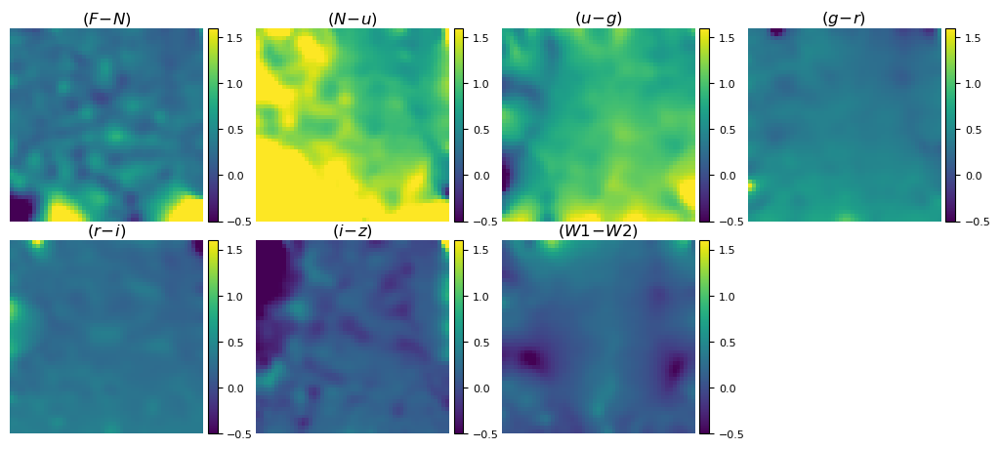

In [17]:
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import numpy as np
from mpl_toolkits.axes_grid1 import make_axes_locatable

# Create larger figure with better aspect for square subplots
fig = plt.figure(figsize=(13, 11.7))

# Outer grid: 2 rows, 1 column
outer_grid = gridspec.GridSpec(2, 1, height_ratios=[1, 1], hspace=0.17)

# Inner grid: 2x4 with tighter spacing
inner_grid_2x4 = gridspec.GridSpecFromSubplotSpec(
    2, 4, subplot_spec=outer_grid[0], wspace=0.0, hspace=0.1)

colors = [r'$(F\!-\!N)$', r'$(N\!-\!u)$', r'$(u\!-\!g)$', r'$(g\!-\!r)$',
          r'$(r\!-\!i)$', r'$(i\!-\!z)$', r'$(W1\!-\!W2)$']

codebook = sm._normalizer.denormalize_by(sm.data_raw, sm.codebook.matrix)

for ind in range(7):  # Only 7 maps
    ax = fig.add_subplot(inner_grid_2x4[ind])
    mp = codebook[:, ind].reshape(sm.codebook.mapsize[0], sm.codebook.mapsize[1])
    im = ax.imshow(mp, origin='lower', cmap='viridis', aspect='equal', vmin=-0.5, vmax=1.6)

    # Remove axis ticks
    ax.tick_params(axis='both', which='major', labelsize=2)
    ax.axis('off')

    # Add subplot label on top of each plot
    ax.set_title(colors[ind], fontsize=12, pad=4)

    # Add colorbar without label
    divider = make_axes_locatable(ax)
    cax = divider.append_axes("right", size="5%", pad=0.05)
    cbar = plt.colorbar(im, cax=cax)
    cbar.ax.tick_params(labelsize=8)

# Final layout and saving
plt.tight_layout(rect=[0, 0, 1, 0.98])
plt.savefig('trainingWISEcolors_square_titles.png', dpi=300)


# Mapping test AGN sample onto the trained SOM

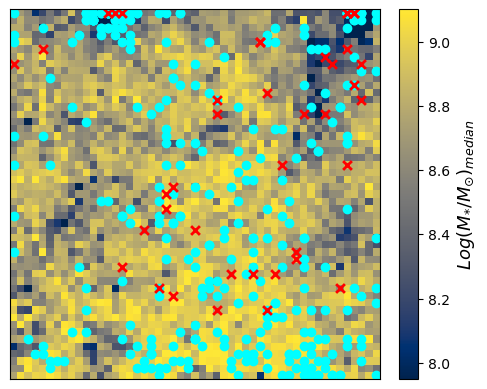

In [19]:
import matplotlib.pyplot as plt
import numpy as np

fig, ax = plt.subplots()

# Show image
cf = ax.imshow(surakh(med_r), origin='lower', cmap='cividis', vmin=7.95, vmax=9.1)

# Create colorbar and set larger label font size
cbar = plt.colorbar(cf, fraction=0.046, pad=0.04)
cbar.set_label(r'$Log(M_{*}/M_{\odot})_{median}$', fontsize=13)

# Remove x and y ticks
ax.set_xticks([])
ax.set_yticks([])

# Prepare data
AGNs = np.array([fnAGN, nuAGN, ugAGN, grAGN, riAGN, izAGN, w12AGN])
AGNc = AGNs.T

cors = np.array([fnc, nuc, ugc, grc, ric, izc, w12c])
corst = cors.T

starB = np.array([fns, nus, ugs, grs, ris, izs, w12s])
StarB = starB.T

targe = np.array([fnt, nut, ugt, grt, rit, izt, w12t])
targetJ1205 = targe.T

# Map AGNs
lines_BMU = sm.bmu_ind_to_xy(sm.project_data(AGNc))
xAGN, yAGN = np.zeros(len(lines_BMU)), np.zeros(len(lines_BMU))
for k, i in enumerate(lines_BMU):
    xAGN[k], yAGN[k] = i[0], i[1]

# Map coronal-line AGNs
linesc_BMU = sm.bmu_ind_to_xy(sm.project_data(corst))
xc, yc = np.zeros(len(linesc_BMU)), np.zeros(len(linesc_BMU))
for k, i in enumerate(linesc_BMU):
    xc[k], yc[k] = i[0], i[1]

# Map WISE starbursts
liness_BMU = sm.bmu_ind_to_xy(sm.project_data(StarB))
xs, ys = np.zeros(len(liness_BMU)), np.zeros(len(liness_BMU))
for k, i in enumerate(liness_BMU):
    xs[k], ys[k] = i[0], i[1]

# Map J1205
linest_BMU = sm.bmu_ind_to_xy(sm.project_data(targetJ1205))
xt, yt = np.zeros(len(linest_BMU)), np.zeros(len(linest_BMU))
for k, i in enumerate(linest_BMU):
    xt[k], yt[k] = i[0], i[1]

# Scatter overlays
plt.scatter(yAGN, xAGN, color='#00FFFF', marker='o')                        # All AGNs
plt.scatter(yc, xc, color='red', marker='x', linewidths=2, s=40)            # Thicker red x markers
# plt.scatter(yt, xt, color='blue', marker='x')                             # Optional target

# Save figure
plt.savefig('Coronal.png', dpi=300)
plt.show()


In [20]:
# Make sure your med_r grid is cleaned using your own surakh function
med_r_filled = surakh(med_r)

# Convert SOM coordinates of coronal-line AGNs to integers for indexing
xc_int = xc.astype(int)
yc_int = yc.astype(int)

# Index med_r using the SOM coordinates to get cell masses
coronal_cell_masses = med_r_filled[xc_int, yc_int]

# Compute the median of those cell stellar masses
median_mass_coronal_cells = np.median(coronal_cell_masses)

# Print or log the result
print("Median stellar mass of SOM cells hosting coronal-line emitters:", median_mass_coronal_cells)


Median stellar mass of SOM cells hosting coronal-line emitters: 8.690456641499999


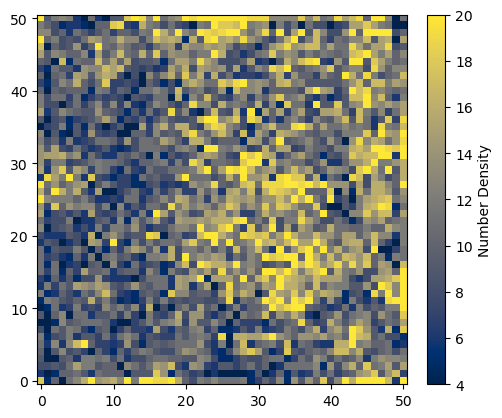

In [21]:
fig, ax = plt.subplots()

cf=ax.imshow(surakh(ND),origin='lower',cmap='cividis',vmin=4,vmax=20)
plt.colorbar(cf, label='Number Density', fraction=0.046, pad=0.04)

AGNs = np.array([fnAGN, nuAGN, ugAGN, grAGN, riAGN, izAGN, w12AGN])
AGNc = AGNs.T

#finding the best matching unit for mapping AGNs onto the trained SOM
lines_BMU = sm.bmu_ind_to_xy(sm.project_data(AGNc))

xAGN,yAGN=np.zeros(len(lines_BMU)),np.zeros(len(lines_BMU))
k=0
for i in lines_BMU:
    xAGN[k]=i[0]
    yAGN[k]=i[1]
    k+=1

#plt.scatter(yAGN, xAGN,color='#00FFFF',marker='o') #point!!! plt.imshow sees the array like a matrix! it is not the same as how we fill the array. so X and Y are reversed.
plt.savefig('ND.png', dpi = 300)

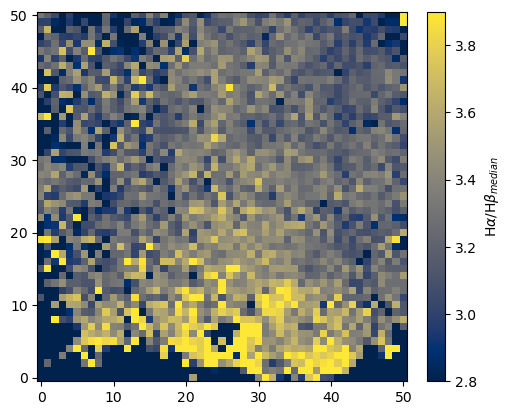

In [22]:

fig, ax = plt.subplots()

cf=ax.imshow(surakh(Hab),origin='lower',cmap='cividis',vmin=2.8,vmax=3.9)
plt.colorbar(cf, label=r'H$\alpha$/H$\beta_{median}$', fraction=0.046, pad=0.04)

AGNs = np.array([fnAGN, nuAGN, ugAGN, grAGN, riAGN, izAGN, w12AGN])
AGNc = AGNs.T

#finding the best matching unit for mapping AGNs onto the trained SOM
lines_BMU = sm.bmu_ind_to_xy(sm.project_data(AGNc))

xAGN,yAGN=np.zeros(len(lines_BMU)),np.zeros(len(lines_BMU))
k=0
for i in lines_BMU:
    xAGN[k]=i[0]
    yAGN[k]=i[1]
    k+=1

#plt.scatter(yAGN, xAGN,color='#00FFFF',marker='o') #point!!! plt.imshow sees the array like a matrix! it is not the same as how we fill the array. so X and Y are reversed.
plt.savefig('Hab.png', dpi = 300)

In [23]:
O3G=np.log10(OIIIclean)/g_clean

O3g=np.zeros([msz0,msz1])
arar=np.zeros([msz0,msz1])
for i in range(msz0):
    for j in range(msz1):
        unja=(x==i)&(y==j)
        O3g[i,j]=(np.nanmedian(np.log10(OIIIclean[unja])/g_clean[unja]))
        arar[i,j]=(np.nanmedian(Halphabeta[unja]))

/var/folders/5z/mxcl46zj3p76_rgxd645pmzr0000gn/T/ipykernel_85598/2683972467.py:1: RuntimeWarning: divide by zero encountered in log10
  O3G=np.log10(OIIIclean)/g_clean
/var/folders/5z/mxcl46zj3p76_rgxd645pmzr0000gn/T/ipykernel_85598/2683972467.py:1: RuntimeWarning: invalid value encountered in log10
  O3G=np.log10(OIIIclean)/g_clean
/var/folders/5z/mxcl46zj3p76_rgxd645pmzr0000gn/T/ipykernel_85598/2683972467.py:8: RuntimeWarning: divide by zero encountered in log10
  O3g[i,j]=(np.nanmedian(np.log10(OIIIclean[unja])/g_clean[unja]))
/var/folders/5z/mxcl46zj3p76_rgxd645pmzr0000gn/T/ipykernel_85598/2683972467.py:8: RuntimeWarning: invalid value encountered in log10
  O3g[i,j]=(np.nanmedian(np.log10(OIIIclean[unja])/g_clean[unja]))
/Users/sogolsanjaripour/anaconda3/lib/python3.10/site-packages/numpy/lib/nanfunctions.py:1215: RuntimeWarning: Mean of empty slice
  return np.nanmean(a, axis, out=out, keepdims=keepdims)


/var/folders/5z/mxcl46zj3p76_rgxd645pmzr0000gn/T/ipykernel_85598/1057006849.py:14: RuntimeWarning: invalid value encountered in divide
  O32[i,j]=(np.nanmedian(OIIIclean[unja]/OIIclean[unja]))
/var/folders/5z/mxcl46zj3p76_rgxd645pmzr0000gn/T/ipykernel_85598/1057006849.py:15: RuntimeWarning: divide by zero encountered in log10
  O3zO2[i,j]=(np.nanmedian(np.log10(OIIIclean[unja])/(OIIclean[unja]*z_clean[unja])))
/var/folders/5z/mxcl46zj3p76_rgxd645pmzr0000gn/T/ipykernel_85598/1057006849.py:15: RuntimeWarning: invalid value encountered in log10
  O3zO2[i,j]=(np.nanmedian(np.log10(OIIIclean[unja])/(OIIclean[unja]*z_clean[unja])))
/Users/sogolsanjaripour/anaconda3/lib/python3.10/site-packages/numpy/lib/nanfunctions.py:1217: RuntimeWarning: All-NaN slice encountered
  r, k = function_base._ureduce(a, func=_nanmedian, axis=axis, out=out,


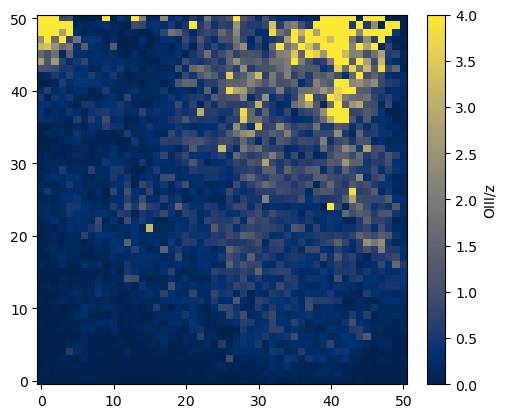

In [24]:
O32=np.zeros([msz0,msz1])
O3z=np.zeros([msz0,msz1])
O3g=np.zeros([msz0,msz1])
O3zO2=np.zeros([msz0,msz1])

a = (OIIIclean > 0)&(OIIclean > 0)
z = (OIIIclean > 0)&(z_clean > 0)
b = (OIIIclean > 0)&(z_clean > 0)&(OIIclean > 0)

for i in range(msz0):
    for j in range(msz1):
        unja=(x==i)&(y==j)
        O3z[i,j]=(np.nanmedian(OIIIclean[unja]/z_clean[unja]))
        O32[i,j]=(np.nanmedian(OIIIclean[unja]/OIIclean[unja]))
        O3zO2[i,j]=(np.nanmedian(np.log10(OIIIclean[unja])/(OIIclean[unja]*z_clean[unja])))
        O3g[i,j]=(np.nanmedian(OIIIclean[unja]/g_clean[unja]))



fig, ax = plt.subplots()

cf=ax.imshow(surakh(O3z),origin='lower',cmap='cividis',vmin=0, vmax=4)
plt.colorbar(cf, label='OIII/z', fraction=0.046, pad=0.04)

AGNs = np.array([fnAGN, nuAGN, ugAGN, grAGN, riAGN, izAGN, w12AGN])
AGNc = AGNs.T

#finding the best matching unit for mapping AGNs onto the trained SOM
lines_BMU = sm.bmu_ind_to_xy(sm.project_data(AGNc))

xAGN,yAGN=np.zeros(len(lines_BMU)),np.zeros(len(lines_BMU))
k=0
for i in lines_BMU:
    xAGN[k]=i[0]
    yAGN[k]=i[1]
    k+=1

#plt.scatter(yAGN, xAGN,color='#00FFFF',marker='o') #point!!! plt.imshow sees the array like a matrix! it is not the same as how we fill the array. so X and Y are reversed.
plt.savefig('o3z', dpi = 300)

/var/folders/5z/mxcl46zj3p76_rgxd645pmzr0000gn/T/ipykernel_85598/2828740846.py:13: RuntimeWarning: invalid value encountered in divide
  O32[i,j]=(np.nanmedian(OIIIclean[unja]/OIIclean[unja]))
/var/folders/5z/mxcl46zj3p76_rgxd645pmzr0000gn/T/ipykernel_85598/2828740846.py:14: RuntimeWarning: divide by zero encountered in log10
  O3zO2[i,j]=(np.nanmedian(np.log10(OIIIclean[unja])/(OIIclean[unja]*z_clean[unja])))
/var/folders/5z/mxcl46zj3p76_rgxd645pmzr0000gn/T/ipykernel_85598/2828740846.py:14: RuntimeWarning: invalid value encountered in log10
  O3zO2[i,j]=(np.nanmedian(np.log10(OIIIclean[unja])/(OIIclean[unja]*z_clean[unja])))
/Users/sogolsanjaripour/anaconda3/lib/python3.10/site-packages/numpy/lib/nanfunctions.py:1217: RuntimeWarning: All-NaN slice encountered
  r, k = function_base._ureduce(a, func=_nanmedian, axis=axis, out=out,
/Users/sogolsanjaripour/anaconda3/lib/python3.10/site-packages/numpy/lib/nanfunctions.py:1215: RuntimeWarning: Mean of empty slice
  return np.nanmean(a, axi

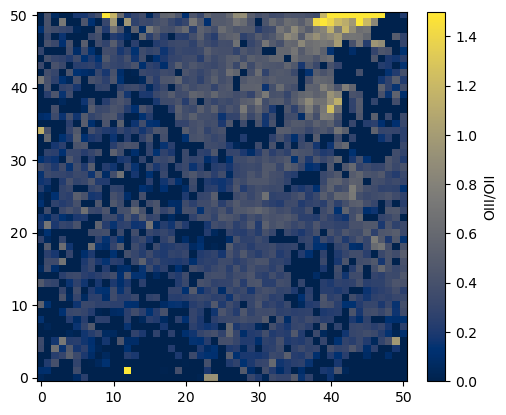

In [25]:
O32=np.zeros([msz0,msz1])
O3z=np.zeros([msz0,msz1])
O3zO2=np.zeros([msz0,msz1])

a = (OIIIclean > 0)&(OIIclean > 0)
z = (OIIIclean > 0)&(z_clean > 0)
b = (OIIIclean > 0)&(z_clean > 0)&(OIIclean > 0)

for i in range(msz0):
    for j in range(msz1):
        unja=(x==i)&(y==j)
        O3z[i,j]=(np.nanmedian(OIIIclean[unja]/z_clean[unja]))
        O32[i,j]=(np.nanmedian(OIIIclean[unja]/OIIclean[unja]))
        O3zO2[i,j]=(np.nanmedian(np.log10(OIIIclean[unja])/(OIIclean[unja]*z_clean[unja])))



fig, ax = plt.subplots()

cf=ax.imshow(surakh(O32),origin='lower',cmap='cividis',vmin=0, vmax=1.5)
plt.colorbar(cf, label='OIII/OII', fraction=0.046, pad=0.04)

AGNs = np.array([fnAGN, nuAGN, ugAGN, grAGN, riAGN, izAGN, w12AGN])
AGNc = AGNs.T

#finding the best matching unit for mapping AGNs onto the trained SOM
lines_BMU = sm.bmu_ind_to_xy(sm.project_data(AGNc))

xAGN,yAGN=np.zeros(len(lines_BMU)),np.zeros(len(lines_BMU))
k=0
for i in lines_BMU:
    xAGN[k]=i[0]
    yAGN[k]=i[1]
    k+=1

#plt.scatter(yAGN, xAGN,color='#00FFFF',marker='o') #point!!! plt.imshow sees the array like a matrix! it is not the same as how we fill the array. so X and Y are reversed.
plt.savefig('o32', dpi = 300)

/var/folders/5z/mxcl46zj3p76_rgxd645pmzr0000gn/T/ipykernel_85598/2079051465.py:18: RuntimeWarning: invalid value encountered in divide
  O32[i,j]=(np.nanmedian(OIIIclean[unja]/OIIclean[unja]))
/var/folders/5z/mxcl46zj3p76_rgxd645pmzr0000gn/T/ipykernel_85598/2079051465.py:19: RuntimeWarning: invalid value encountered in divide
  O3zO2[i,j]=(np.nanmedian(OIIIclean[unja]/(OIIclean[unja]*z_clean[unja])))
/var/folders/5z/mxcl46zj3p76_rgxd645pmzr0000gn/T/ipykernel_85598/2079051465.py:22: RuntimeWarning: invalid value encountered in divide
  O3iO2[i,j]=(np.nanmedian(OIIIclean[unja]/(OIIclean[unja]*i_clean[unja])))
/Users/sogolsanjaripour/anaconda3/lib/python3.10/site-packages/numpy/lib/nanfunctions.py:1217: RuntimeWarning: All-NaN slice encountered
  r, k = function_base._ureduce(a, func=_nanmedian, axis=axis, out=out,
/Users/sogolsanjaripour/anaconda3/lib/python3.10/site-packages/numpy/lib/nanfunctions.py:1215: RuntimeWarning: Mean of empty slice
  return np.nanmean(a, axis, out=out, keepdim

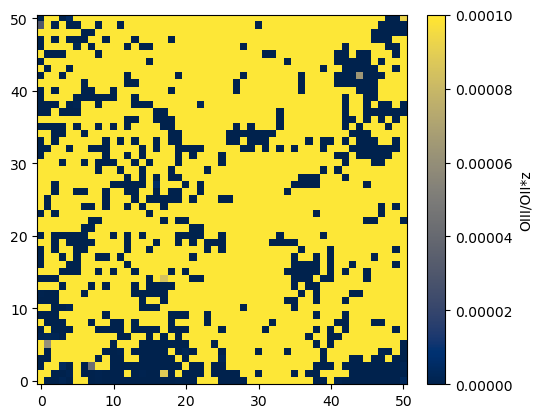

In [26]:
O32=np.zeros([msz0,msz1])
O3z=np.zeros([msz0,msz1])
O2z=np.zeros([msz0,msz1])
O3zO2=np.zeros([msz0,msz1])
O3i=np.zeros([msz0,msz1])
O2i=np.zeros([msz0,msz1])
O3iO2=np.zeros([msz0,msz1])

a = (OIIIclean > 0)&(OIIclean > 0)
z = (OIIIclean > 0)&(z_clean > 0)
b = (OIIIclean > 0)&(z_clean > 0)&(OIIclean > 0)

for i in range(msz0):
    for j in range(msz1):
        unja=(x==i)&(y==j)
        O3z[i,j]=(np.nanmedian(OIIIclean[unja]/z_clean[unja]))
        O2z[i,j]=(np.nanmedian(OIIclean[unja]/z_clean[unja]))
        O32[i,j]=(np.nanmedian(OIIIclean[unja]/OIIclean[unja]))
        O3zO2[i,j]=(np.nanmedian(OIIIclean[unja]/(OIIclean[unja]*z_clean[unja])))
        O3i[i,j]=(np.nanmedian(OIIIclean[unja]/i_clean[unja]))
        O2i[i,j]=(np.nanmedian(OIIclean[unja]/i_clean[unja]))
        O3iO2[i,j]=(np.nanmedian(OIIIclean[unja]/(OIIclean[unja]*i_clean[unja])))



fig, ax = plt.subplots()

cf=ax.imshow(surakh(O3zO2),origin='lower',cmap='cividis',vmin = 0, vmax = 0.0001)
plt.colorbar(cf, label='OIII/OII*z', fraction=0.046, pad=0.04)

AGNs = np.array([fnAGN, nuAGN, ugAGN, grAGN, riAGN, izAGN, w12AGN])
AGNc = AGNs.T

#finding the best matching unit for mapping AGNs onto the trained SOM
lines_BMU = sm.bmu_ind_to_xy(sm.project_data(AGNc))

xAGN,yAGN=np.zeros(len(lines_BMU)),np.zeros(len(lines_BMU))
k=0
for i in lines_BMU:
    xAGN[k]=i[0]
    yAGN[k]=i[1]
    k+=1

#plt.scatter(yAGN, xAGN,color='#00FFFF',marker='o') #point!!! plt.imshow sees the array like a matrix! it is not the same as how we fill the array. so X and Y are reversed.
plt.savefig('o3zo2', dpi = 300)

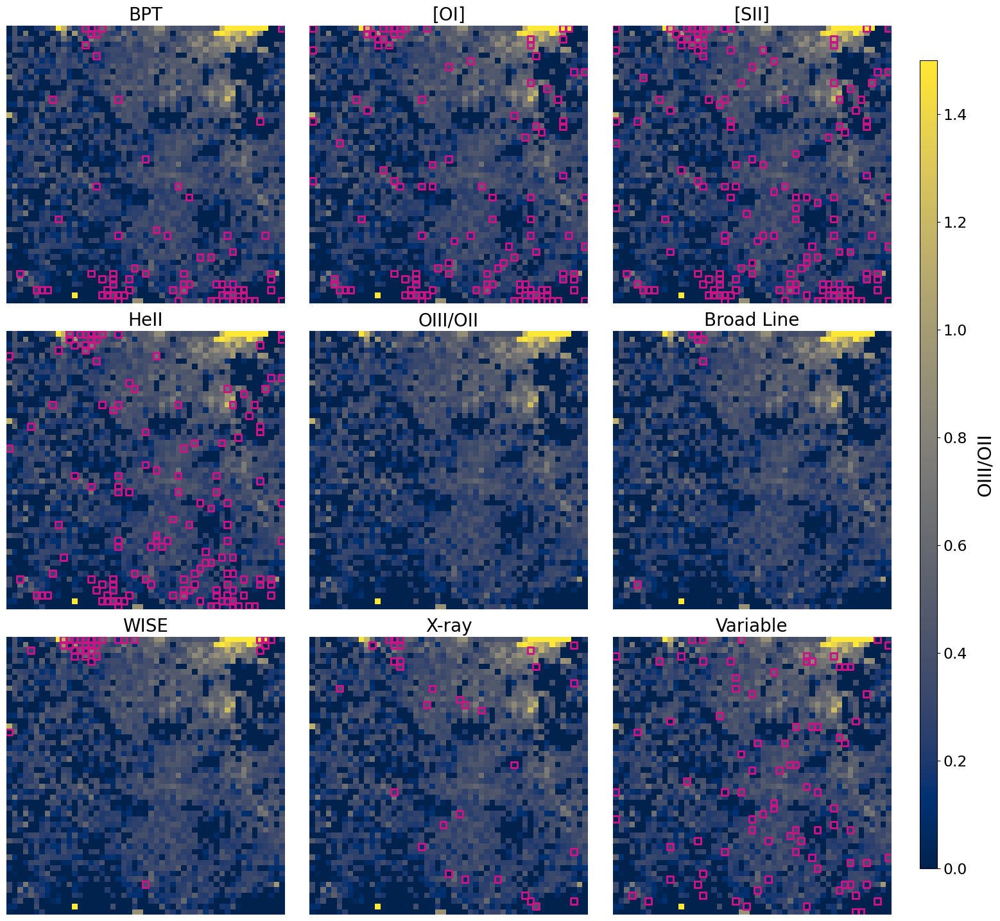

In [28]:
import matplotlib.pyplot as plt
import numpy as np
import matplotlib.gridspec as gridspec
from mpl_toolkits.axes_grid1 import make_axes_locatable

agnflagnames = ['BPT', '[OI]', '[SII]', 'HeII', 'Broad Line', 'WISE', 'X-ray', 'Variable']

# Define layout: 3x3 grid with the center (1,1) as mass map
fig = plt.figure(figsize=(18, 18))
gs = gridspec.GridSpec(3, 3, wspace=0.05, hspace=0.1)

# Mapping AGN flag indices to 3x3 positions excluding the center (1,1)
positions = [(0, 0), (0, 1), (0, 2),
             (1, 0),         (1, 2),
             (2, 0), (2, 1), (2, 2)]

cf = None  # Colorbar handle

# Plot the 8 AGN selection method subplots
for fla in range(8):
    try:
        row, col = positions[fla]
        ax = fig.add_subplot(gs[row, col])

        flagcon = AGN[:][5+fla][conAGN] == 1
        AGNf = np.array([fnAGN[flagcon], nuAGN[flagcon], ugAGN[flagcon],
                         grAGN[flagcon], riAGN[flagcon], izAGN[flagcon], w12AGN[flagcon]])
        AGNflag = AGNf.T
        BMU_AGNflag = sm.bmu_ind_to_xy(sm.project_data(AGNflag))

        xxAGNs, xyAGNs = np.zeros(len(BMU_AGNflag)), np.zeros(len(BMU_AGNflag))
        for k, i in enumerate(BMU_AGNflag):
            xxAGNs[k], xyAGNs[k] = i[0], i[1]

        cf = ax.imshow(surakh(O32), origin='lower', cmap='cividis', vmin=0, vmax=1.5)
        ax.scatter(xyAGNs, xxAGNs, marker='s', edgecolor='mediumvioletred',
                   facecolors='none', s=50, linewidth=2.2)
        ax.set_title(agnflagnames[fla], fontsize=20)
        ax.axis('off')

    except Exception as e:
        print(f"Error in flag {agnflagnames[fla]}: {e}")
        continue

# Plot the mass map in the center (1,1)
ax_center = fig.add_subplot(gs[1, 1])
cf = ax_center.imshow(surakh(O32), origin='lower', cmap='cividis',vmin=0, vmax=1.5)
ax_center.set_title(r'OIII/OII', fontsize=20)
ax_center.axis('off')

# Shared colorbar on the right
cbar_ax = fig.add_axes([0.92, 0.15, 0.015, 0.7])  # [left, bottom, width, height]
cbar = fig.colorbar(cf, cax=cbar_ax)
cbar.set_label('OIII/OII', fontsize=21, labelpad=10)
cbar.ax.tick_params(labelsize=17)

# Save and show
plt.savefig("1.png", dpi=300, bbox_inches='tight')
plt.show()


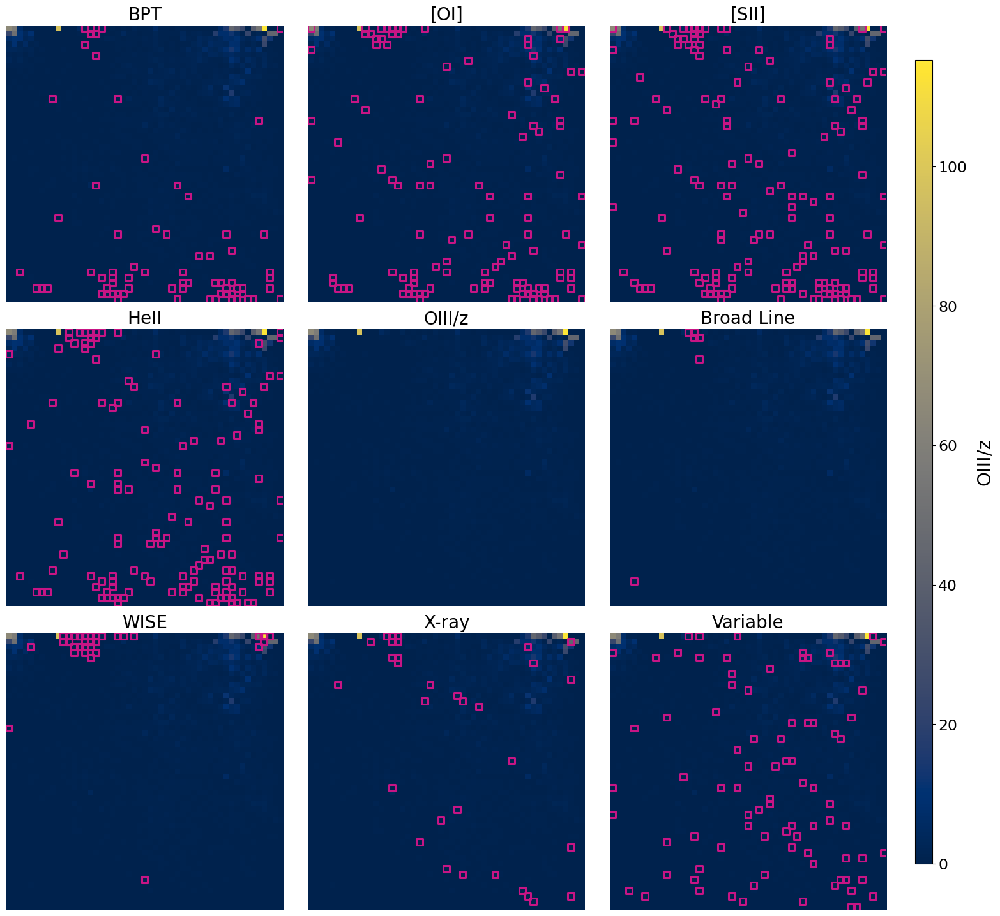

In [29]:
import matplotlib.pyplot as plt
import numpy as np
import matplotlib.gridspec as gridspec
from mpl_toolkits.axes_grid1 import make_axes_locatable

agnflagnames = ['BPT', '[OI]', '[SII]', 'HeII', 'Broad Line', 'WISE', 'X-ray', 'Variable']

# Define layout: 3x3 grid with the center (1,1) as mass map
fig = plt.figure(figsize=(18, 18))
gs = gridspec.GridSpec(3, 3, wspace=0.05, hspace=0.1)

# Mapping AGN flag indices to 3x3 positions excluding the center (1,1)
positions = [(0, 0), (0, 1), (0, 2),
             (1, 0),         (1, 2),
             (2, 0), (2, 1), (2, 2)]

cf = None  # Colorbar handle

# Plot the 8 AGN selection method subplots
for fla in range(8):
    try:
        row, col = positions[fla]
        ax = fig.add_subplot(gs[row, col])

        flagcon = AGN[:][5+fla][conAGN] == 1
        AGNf = np.array([fnAGN[flagcon], nuAGN[flagcon], ugAGN[flagcon],
                         grAGN[flagcon], riAGN[flagcon], izAGN[flagcon], w12AGN[flagcon]])
        AGNflag = AGNf.T
        BMU_AGNflag = sm.bmu_ind_to_xy(sm.project_data(AGNflag))

        xxAGNs, xyAGNs = np.zeros(len(BMU_AGNflag)), np.zeros(len(BMU_AGNflag))
        for k, i in enumerate(BMU_AGNflag):
            xxAGNs[k], xyAGNs[k] = i[0], i[1]

        cf = ax.imshow(surakh(O3z), origin='lower', cmap='cividis')
        ax.scatter(xyAGNs, xxAGNs, marker='s', edgecolor='mediumvioletred',
                   facecolors='none', s=50, linewidth=2.2)
        ax.set_title(agnflagnames[fla], fontsize=20)
        ax.axis('off')

    except Exception as e:
        print(f"Error in flag {agnflagnames[fla]}: {e}")
        continue

# Plot the mass map in the center (1,1)
ax_center = fig.add_subplot(gs[1, 1])
cf = ax_center.imshow(surakh(O3z), origin='lower', cmap='cividis')
ax_center.set_title(r'OIII/z', fontsize=20)
ax_center.axis('off')

# Shared colorbar on the right
cbar_ax = fig.add_axes([0.92, 0.15, 0.015, 0.7])  # [left, bottom, width, height]
cbar = fig.colorbar(cf, cax=cbar_ax)
cbar.set_label('OIII/z', fontsize=21, labelpad=10)
cbar.ax.tick_params(labelsize=17)

# Save and show
plt.savefig("2.png", dpi=300, bbox_inches='tight')
plt.show()


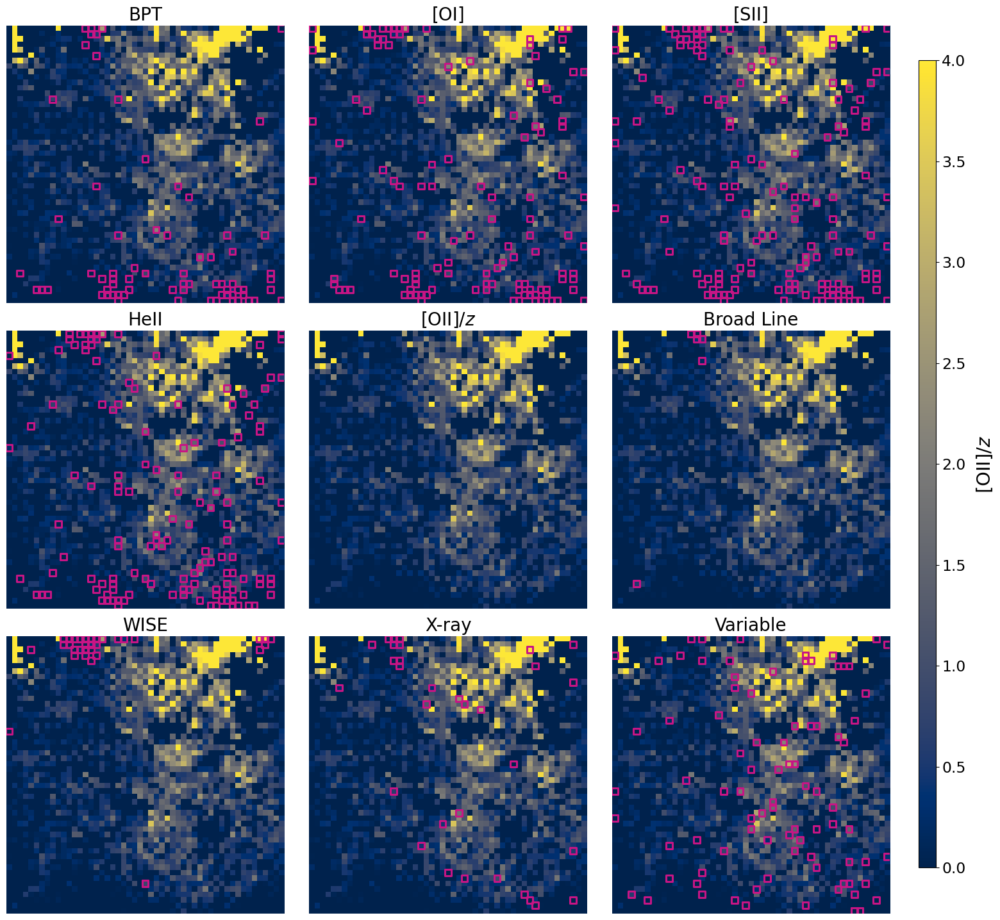

In [30]:
import matplotlib.pyplot as plt
import numpy as np
import matplotlib.gridspec as gridspec
from mpl_toolkits.axes_grid1 import make_axes_locatable

agnflagnames = ['BPT', '[OI]', '[SII]', 'HeII', 'Broad Line', 'WISE', 'X-ray', 'Variable']

# Define layout: 3x3 grid with the center (1,1) as mass map
fig = plt.figure(figsize=(18, 18))
gs = gridspec.GridSpec(3, 3, wspace=0.05, hspace=0.1)

# Mapping AGN flag indices to 3x3 positions excluding the center (1,1)
positions = [(0, 0), (0, 1), (0, 2),
             (1, 0),         (1, 2),
             (2, 0), (2, 1), (2, 2)]

cf = None  # Colorbar handle

# Plot the 8 AGN selection method subplots
for fla in range(8):
    try:
        row, col = positions[fla]
        ax = fig.add_subplot(gs[row, col])

        flagcon = AGN[:][5+fla][conAGN] == 1
        AGNf = np.array([fnAGN[flagcon], nuAGN[flagcon], ugAGN[flagcon],
                         grAGN[flagcon], riAGN[flagcon], izAGN[flagcon], w12AGN[flagcon]])
        AGNflag = AGNf.T
        BMU_AGNflag = sm.bmu_ind_to_xy(sm.project_data(AGNflag))

        xxAGNs, xyAGNs = np.zeros(len(BMU_AGNflag)), np.zeros(len(BMU_AGNflag))
        for k, i in enumerate(BMU_AGNflag):
            xxAGNs[k], xyAGNs[k] = i[0], i[1]

        cf = ax.imshow(surakh(O2z), origin='lower', cmap='cividis',vmin=0, vmax=4)
        ax.scatter(xyAGNs, xxAGNs, marker='s', edgecolor='mediumvioletred',
                   facecolors='none', s=50, linewidth=2.2)
        ax.set_title(agnflagnames[fla], fontsize=20)
        ax.axis('off')

    except Exception as e:
        print(f"Error in flag {agnflagnames[fla]}: {e}")
        continue

# Plot the mass map in the center (1,1)
ax_center = fig.add_subplot(gs[1, 1])
cf = ax_center.imshow(surakh(O2z), origin='lower', cmap='cividis',vmin=0, vmax=4)
ax_center.set_title(r'[OII]/$z$', fontsize=20)
ax_center.axis('off')

# Shared colorbar on the right
cbar_ax = fig.add_axes([0.92, 0.15, 0.015, 0.7])  # [left, bottom, width, height]
cbar = fig.colorbar(cf, cax=cbar_ax)
cbar.set_label(r'[OII]/$z$', fontsize=21, labelpad=10)
cbar.ax.tick_params(labelsize=17)

# Save and show
plt.savefig("5.png", dpi=300, bbox_inches='tight')
plt.show()


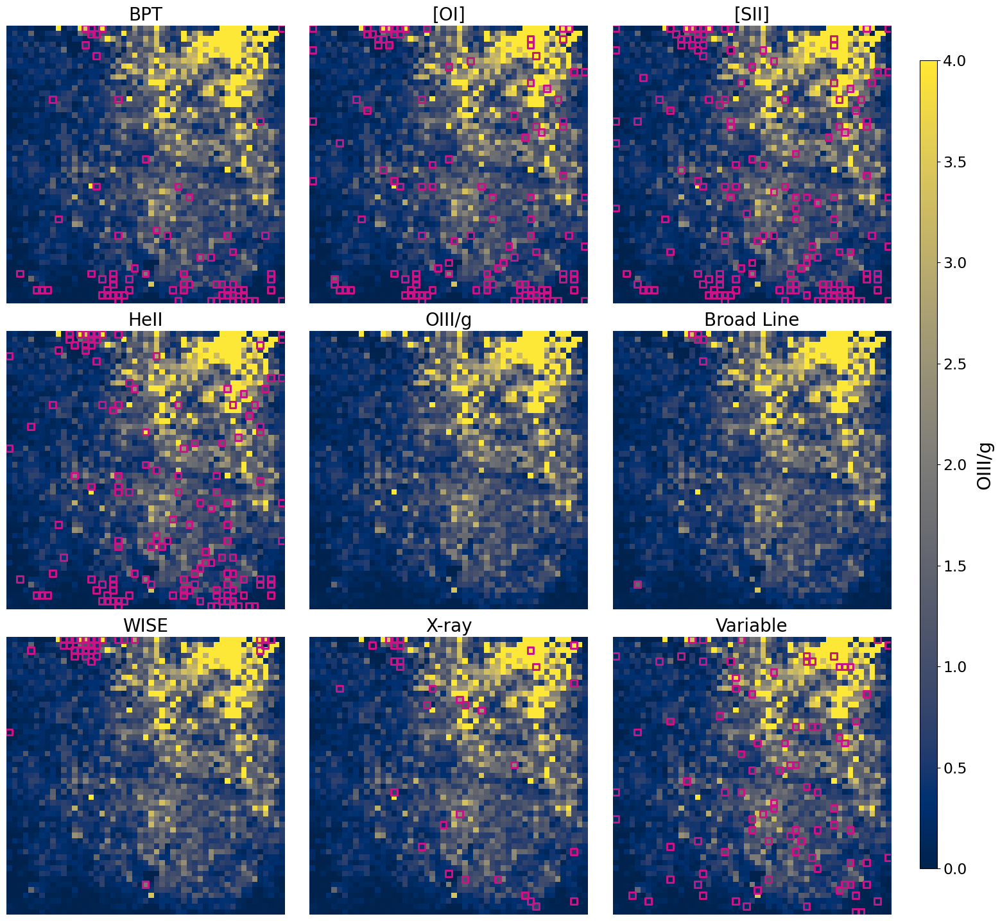

In [31]:
import matplotlib.pyplot as plt
import numpy as np
import matplotlib.gridspec as gridspec
from mpl_toolkits.axes_grid1 import make_axes_locatable

agnflagnames = ['BPT', '[OI]', '[SII]', 'HeII', 'Broad Line', 'WISE', 'X-ray', 'Variable']

# Define layout: 3x3 grid with the center (1,1) as mass map
fig = plt.figure(figsize=(18, 18))
gs = gridspec.GridSpec(3, 3, wspace=0.05, hspace=0.1)

# Mapping AGN flag indices to 3x3 positions excluding the center (1,1)
positions = [(0, 0), (0, 1), (0, 2),
             (1, 0),         (1, 2),
             (2, 0), (2, 1), (2, 2)]

cf = None  # Colorbar handle

# Plot the 8 AGN selection method subplots
for fla in range(8):
    try:
        row, col = positions[fla]
        ax = fig.add_subplot(gs[row, col])

        flagcon = AGN[:][5+fla][conAGN] == 1
        AGNf = np.array([fnAGN[flagcon], nuAGN[flagcon], ugAGN[flagcon],
                         grAGN[flagcon], riAGN[flagcon], izAGN[flagcon], w12AGN[flagcon]])
        AGNflag = AGNf.T
        BMU_AGNflag = sm.bmu_ind_to_xy(sm.project_data(AGNflag))

        xxAGNs, xyAGNs = np.zeros(len(BMU_AGNflag)), np.zeros(len(BMU_AGNflag))
        for k, i in enumerate(BMU_AGNflag):
            xxAGNs[k], xyAGNs[k] = i[0], i[1]

        cf = ax.imshow(surakh(O3g), origin='lower', cmap='cividis',vmin=0, vmax=4)
        ax.scatter(xyAGNs, xxAGNs, marker='s', edgecolor='mediumvioletred',
                   facecolors='none', s=50, linewidth=2.2)
        ax.set_title(agnflagnames[fla], fontsize=20)
        ax.axis('off')

    except Exception as e:
        print(f"Error in flag {agnflagnames[fla]}: {e}")
        continue

# Plot the mass map in the center (1,1)
ax_center = fig.add_subplot(gs[1, 1])
cf = ax_center.imshow(surakh(O3g), origin='lower', cmap='cividis',vmin=0, vmax=4)
ax_center.set_title(r'OIII/g', fontsize=20)
ax_center.axis('off')

# Shared colorbar on the right
cbar_ax = fig.add_axes([0.92, 0.15, 0.015, 0.7])  # [left, bottom, width, height]
cbar = fig.colorbar(cf, cax=cbar_ax)
cbar.set_label('OIII/g', fontsize=21, labelpad=10)
cbar.ax.tick_params(labelsize=17)

# Save and show
plt.savefig("4.png", dpi=300, bbox_inches='tight')
plt.show()


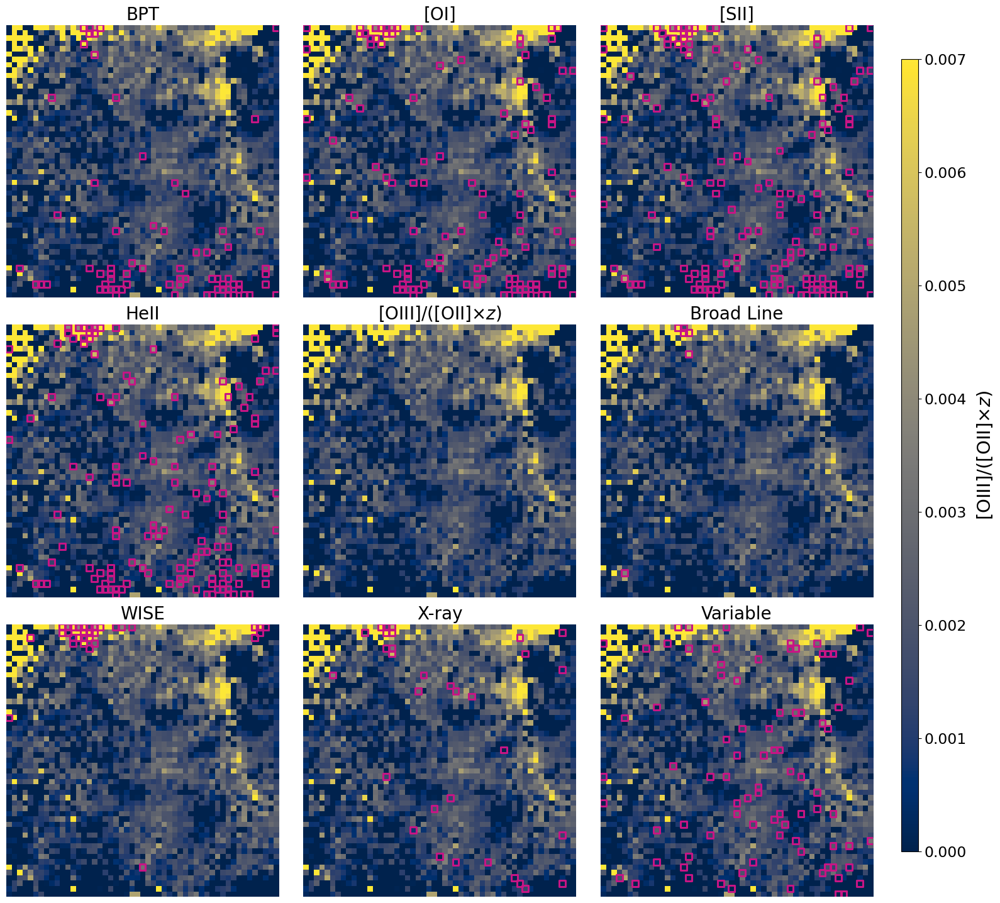

In [32]:
import matplotlib.pyplot as plt
import numpy as np
import matplotlib.gridspec as gridspec
from mpl_toolkits.axes_grid1 import make_axes_locatable

agnflagnames = ['BPT', '[OI]', '[SII]', 'HeII', 'Broad Line', 'WISE', 'X-ray', 'Variable']

# Define layout: 3x3 grid with the center (1,1) as mass map
fig = plt.figure(figsize=(18, 18))
gs = gridspec.GridSpec(3, 3, wspace=0.05, hspace=0.1)

# Mapping AGN flag indices to 3x3 positions excluding the center (1,1)
positions = [(0, 0), (0, 1), (0, 2),
             (1, 0),         (1, 2),
             (2, 0), (2, 1), (2, 2)]

cf = None  # Colorbar handle

# Plot the 8 AGN selection method subplots
for fla in range(8):
    try:
        row, col = positions[fla]
        ax = fig.add_subplot(gs[row, col])

        flagcon = AGN[:][5+fla][conAGN] == 1
        AGNf = np.array([fnAGN[flagcon], nuAGN[flagcon], ugAGN[flagcon],
                         grAGN[flagcon], riAGN[flagcon], izAGN[flagcon], w12AGN[flagcon]])
        AGNflag = AGNf.T
        BMU_AGNflag = sm.bmu_ind_to_xy(sm.project_data(AGNflag))

        xxAGNs, xyAGNs = np.zeros(len(BMU_AGNflag)), np.zeros(len(BMU_AGNflag))
        for k, i in enumerate(BMU_AGNflag):
            xxAGNs[k], xyAGNs[k] = i[0], i[1]

        cf = ax.imshow(surakh(O3zO2), origin='lower', cmap='cividis',vmin = 0, vmax = 0.007)
        ax.scatter(xyAGNs, xxAGNs, marker='s', edgecolor='mediumvioletred',
                   facecolors='none', s=50, linewidth=2.2)
        ax.set_title(agnflagnames[fla], fontsize=20)
        ax.axis('off')

    except Exception as e:
        print(f"Error in flag {agnflagnames[fla]}: {e}")
        continue

# Plot the mass map in the center (1,1)
ax_center = fig.add_subplot(gs[1, 1])
cf = ax_center.imshow(surakh(O3zO2), origin='lower', cmap='cividis',vmin = 0, vmax = 0.007)
ax_center.set_title(r'[OIII]/([OII]$\times z$)', fontsize=20)
ax_center.axis('off')

# Shared colorbar on the right
cbar_ax = fig.add_axes([0.92, 0.15, 0.015, 0.7])  # [left, bottom, width, height]
cbar = fig.colorbar(cf, cax=cbar_ax)
cbar.set_label(r'[OIII]/([OII]$\times z$)', fontsize=21, labelpad=10)
cbar.ax.tick_params(labelsize=17)

# Save and show
plt.savefig("3.png", dpi=300, bbox_inches='tight')
plt.show()


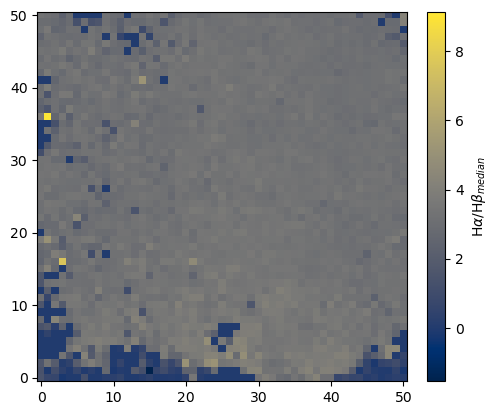

In [33]:
fig, ax = plt.subplots()

cf=ax.imshow(surakh(arar),origin='lower',cmap='cividis')
plt.colorbar(cf, label=r'H$\alpha$/H$\beta_{median}$', fraction=0.046, pad=0.04)

AGNs = np.array([fnAGN, nuAGN, ugAGN, grAGN, riAGN, izAGN, w12AGN])
AGNc = AGNs.T

#finding the best matching unit for mapping AGNs onto the trained SOM
lines_BMU = sm.bmu_ind_to_xy(sm.project_data(AGNc))

xAGN,yAGN=np.zeros(len(lines_BMU)),np.zeros(len(lines_BMU))
k=0
for i in lines_BMU:
    xAGN[k]=i[0]
    yAGN[k]=i[1]
    k+=1

#plt.scatter(yAGN, xAGN,color='#00FFFF',marker='o') #point!!! plt.imshow sees the array like a matrix! it is not the same as how we fill the array. so X and Y are reversed.
plt.savefig('Hab.png', dpi = 300)

/var/folders/5z/mxcl46zj3p76_rgxd645pmzr0000gn/T/ipykernel_85598/1907261649.py:56: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(rect=[0, 0, 1, 1])


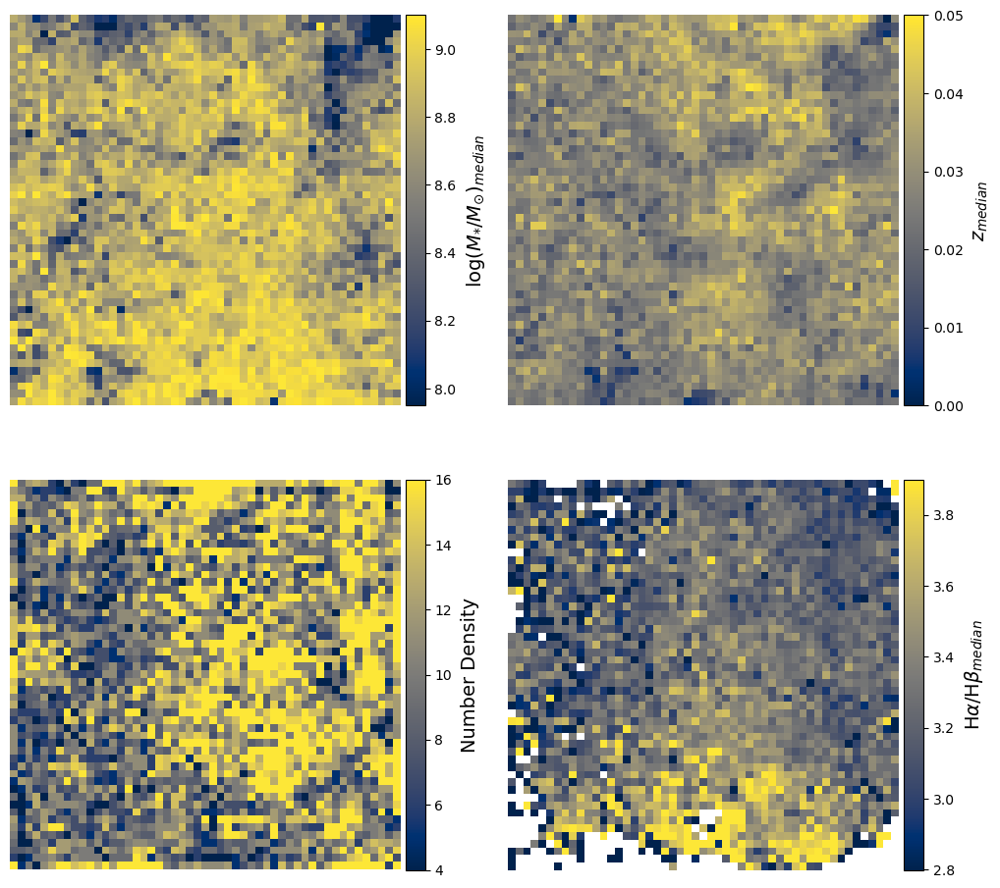

In [34]:
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import numpy as np
from mpl_toolkits.axes_grid1 import make_axes_locatable

# Setup figure and tight 2x2 grid
fig = plt.figure(figsize=(12, 12))
grid = gridspec.GridSpec(2, 2, wspace=0.2, hspace=0.05)

# -- Mass Plot --
ax = fig.add_subplot(grid[0, 0])
cf = ax.imshow(surakh(med_r), origin='lower', cmap='cividis', vmin=7.95, vmax=9.1)
divider = make_axes_locatable(ax)
cax = divider.append_axes("right", size="5%", pad=0.05)
cbar = plt.colorbar(cf, cax=cax)
cbar.set_label(r'$\log(M_{*}/M_{\odot})_{median}$', fontsize=14, labelpad=6)
ax.axis('off')

# -- Redshift Plot --
ax = fig.add_subplot(grid[0, 1])
cf = ax.imshow(surakh(med_z), origin='lower', cmap='cividis', vmin=0.0, vmax=0.05)
divider = make_axes_locatable(ax)
cax = divider.append_axes("right", size="5%", pad=0.05)
cbar = plt.colorbar(cf, cax=cax)
cbar.set_label(r'$z_{median}$', fontsize=14, labelpad=6)
ax.axis('off')

# -- Number Density Plot --
ax = fig.add_subplot(grid[1, 0])
cf = ax.imshow(surakh(ND), origin='lower', cmap='cividis', vmin=4, vmax=16)
divider = make_axes_locatable(ax)
cax = divider.append_axes("right", size="5%", pad=0.05)
cbar = plt.colorbar(cf, cax=cax)
cbar.set_label('Number Density', fontsize=14, labelpad=6)
ax.axis('off')

# -- Halpha/Hbeta Plot with red for zero values --
ax = fig.add_subplot(grid[1, 1])
hab_data = surakh(Hab)

# Mask zero (or near-zero) values instead of NaNs
masked_hab_data = np.ma.masked_where(hab_data < 1.2, hab_data)

cmap = plt.get_cmap('cividis').copy()
cmap.set_bad(color='white')  # Set red for masked (i.e., zero) values

cf = ax.imshow(masked_hab_data, origin='lower', cmap=cmap, vmin=2.8, vmax=3.9)
divider = make_axes_locatable(ax)
cax = divider.append_axes("right", size="5%", pad=0.05)
cbar = plt.colorbar(cf, cax=cax)
cbar.set_label(r'H$\alpha$/H$\beta_{median}$', fontsize=14, labelpad=6)
ax.axis('off')


# Final layout and save
plt.tight_layout(rect=[0, 0, 1, 1])
plt.savefig('SOM_2x2_summary_cividis.png', dpi=300)

# Different AGN selection

16.0
15.0
14.0
15.0
14.0
14.0
17.0
done
12.0
16.0
0.0
13.0
15.0
14.0
14.0
15.0
10.0
14.0
17.0
10.0
14.0
14.0
11.0
15.0
12.0
11.0
21.0
13.0
0.0
16.0
13.0
15.0
12.0
16.0
17.0
13.0
done
12.0
10.0
16.0
0.0
15.0
15.0
14.0
14.0
15.0
11.0
14.0
21.0
20.0
15.0
10.0
14.0
11.0
15.0
16.0
12.0
21.0
0.0
16.0
13.0
16.0
13.0
12.0
15.0
17.0
done
14.0
16.0
15.0
15.0
14.0
15.0
11.0
14.0
13.0
20.0
14.0
15.0
11.0
12.0
0.0
16.0
11.0
16.0
16.0
15.0
17.0
9.0
done
16.0
15.0
15.0
14.0
14.0
15.0
done
14.0
13.0
12.0
10.0
16.0
15.0
13.0
14.0
15.0
14.0
14.0
15.0
11.0
10.0
14.0
13.0
10.0
4.0
13.0
17.0
15.0
20.0
15.0
10.0
12.0
14.0
14.0
11.0
16.0
14.0
23.0
16.0
15.0
11.0
13.0
13.0
16.0
14.0
12.0
23.0
21.0
13.0
15.0
16.0
11.0
13.0
10.0
16.0
11.0
13.0
15.0
12.0
12.0
16.0
15.0
17.0
13.0
done
X WISE = [14. 13. 46. 12. 47. 10. 16. 48. 15. 13. 14. 15. 25. 14. 47. 47. 14. 15.
 11. 10. 14. 47. 46. 13. 10.  4. 13. 17. 15. 20. 47. 25. 15. 47. 10. 12.
 47. 14. 14. 11. 48. 16. 14. 46. 23. 16. 15. 11. 13. 13. 16. 46. 47. 47.
 47.

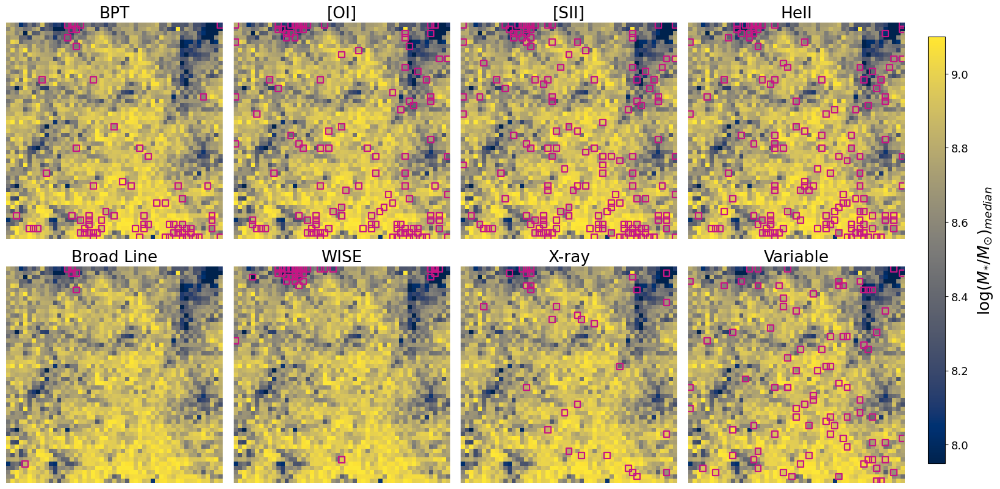

In [35]:
import matplotlib.pyplot as plt
import numpy as np
import matplotlib.gridspec as gridspec

agnflagnames = ['BPT','[OI]','[SII]','HeII','Broad Line','WISE','X-ray', 'Variable']

# Create figure and gridspec with reduced row spacing
fig = plt.figure(figsize=(19, 10))
gs = gridspec.GridSpec(2, 4, wspace=0.05, hspace=0.08)

cf = None  # Will hold the last imshow object for the colorbar

for fla in range(8):
    try:
        flagcon = AGN[:][5+fla][conAGN] == 1
        AGNf = np.array([fnAGN[flagcon], nuAGN[flagcon], ugAGN[flagcon],
                         grAGN[flagcon], riAGN[flagcon], izAGN[flagcon], w12AGN[flagcon]])
        AGNflag = AGNf.T
        BMU_AGNflag = sm.bmu_ind_to_xy(sm.project_data(AGNflag))

        xxAGNs, xyAGNs = np.zeros(len(BMU_AGNflag)), np.zeros(len(BMU_AGNflag))
        for k, i in enumerate(BMU_AGNflag):
            xxAGNs[k], xyAGNs[k] = i[0], i[1]

        ax = fig.add_subplot(gs[fla])
        ax.set_title(agnflagnames[fla], fontsize=19)

        cf = ax.imshow(surakh(med_r), origin='lower', cmap='cividis', vmin=7.95, vmax=9.1)

        ax.scatter(xyAGNs, xxAGNs, marker='s', edgecolor='mediumvioletred',
                   facecolors='none', s=50, linewidth=1.6)
        ax.axis('off')
        for i in range(len(xyAGNs)):
            if ((xyAGNs[i] < 25)&(xxAGNs[i] > 45)):
                print(xyAGNs[i])
        print('done')
        if fla == 5:
            print('X WISE =', xyAGNs)
            print('Y WISE =', xxAGNs)

    except Exception as e:
        print(f"Error with flag {agnflagnames[fla]}: {e}")
        continue

# Add a shared vertical colorbar on the right
cbar_ax = fig.add_axes([0.92, 0.15, 0.015, 0.7])  # [left, bottom, width, height]
cbar = fig.colorbar(cf, cax=cbar_ax)
cbar.set_label(r'$\log(M_{*}/M_{\odot})_{median}$', fontsize=19, labelpad=9)
cbar.ax.tick_params(labelsize=13)  # Increase tick label font size

plt.savefig("AGN_shared_colorbar_tightrows.png", dpi=300, bbox_inches='tight')


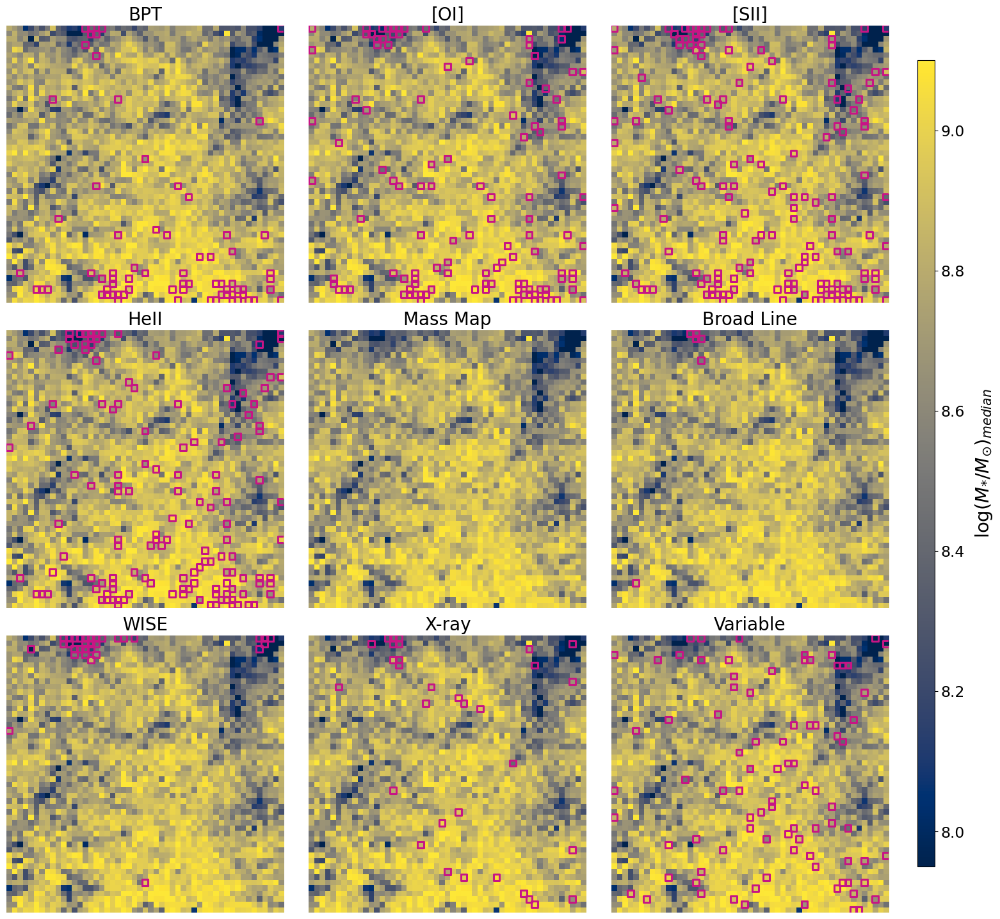

In [36]:
import matplotlib.pyplot as plt
import numpy as np
import matplotlib.gridspec as gridspec
from mpl_toolkits.axes_grid1 import make_axes_locatable

agnflagnames = ['BPT', '[OI]', '[SII]', 'HeII', 'Broad Line', 'WISE', 'X-ray', 'Variable']

# Define layout: 3x3 grid with the center (1,1) as mass map
fig = plt.figure(figsize=(18, 18))
gs = gridspec.GridSpec(3, 3, wspace=0.05, hspace=0.1)

# Mapping AGN flag indices to 3x3 positions excluding the center (1,1)
positions = [(0, 0), (0, 1), (0, 2),
             (1, 0),         (1, 2),
             (2, 0), (2, 1), (2, 2)]

cf = None  # Colorbar handle

# Plot the 8 AGN selection method subplots
for fla in range(8):
    try:
        row, col = positions[fla]
        ax = fig.add_subplot(gs[row, col])

        flagcon = AGN[:][5+fla][conAGN] == 1
        AGNf = np.array([fnAGN[flagcon], nuAGN[flagcon], ugAGN[flagcon],
                         grAGN[flagcon], riAGN[flagcon], izAGN[flagcon], w12AGN[flagcon]])
        AGNflag = AGNf.T
        BMU_AGNflag = sm.bmu_ind_to_xy(sm.project_data(AGNflag))

        xxAGNs, xyAGNs = np.zeros(len(BMU_AGNflag)), np.zeros(len(BMU_AGNflag))
        for k, i in enumerate(BMU_AGNflag):
            xxAGNs[k], xyAGNs[k] = i[0], i[1]

        cf = ax.imshow(surakh(med_r), origin='lower', cmap='cividis', vmin=7.95, vmax=9.1)
        ax.scatter(xyAGNs, xxAGNs, marker='s', edgecolor='mediumvioletred',
                   facecolors='none', s=50, linewidth=2.2)
        ax.set_title(agnflagnames[fla], fontsize=20)
        ax.axis('off')

    except Exception as e:
        print(f"Error in flag {agnflagnames[fla]}: {e}")
        continue

# Plot the mass map in the center (1,1)
ax_center = fig.add_subplot(gs[1, 1])
cf = ax_center.imshow(surakh(med_r), origin='lower', cmap='cividis', vmin=7.95, vmax=9.1)
ax_center.set_title(r'Mass Map', fontsize=20)
ax_center.axis('off')

# Shared colorbar on the right
cbar_ax = fig.add_axes([0.92, 0.15, 0.015, 0.7])  # [left, bottom, width, height]
cbar = fig.colorbar(cf, cax=cbar_ax)
cbar.set_label(r'$\log(M_{*}/M_{\odot})_{median}$', fontsize=21, labelpad=10)
cbar.ax.tick_params(labelsize=17)

# Save and show
plt.savefig("AGN_Mass_Center_Grid.png", dpi=300, bbox_inches='tight')
plt.show()


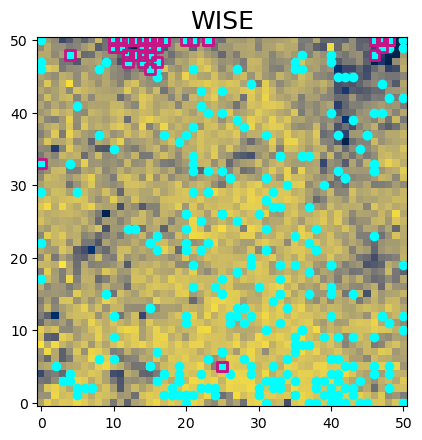

In [37]:
flagcon = AGN[:][5+5][conAGN]== 1
AGNf = np.array([fnAGN[flagcon], nuAGN[flagcon], ugAGN[flagcon], grAGN[flagcon], riAGN[flagcon], izAGN[flagcon], w12AGN[flagcon]])
AGNflag = AGNf.T
BMU_AGNflag = sm.bmu_ind_to_xy(sm.project_data(AGNflag))

xxAGNs,xyAGNs=np.zeros(len(BMU_AGNflag)),np.zeros(len(BMU_AGNflag))
k=0
for i in BMU_AGNflag:
    xxAGNs[k]=i[0]
    xyAGNs[k]=i[1]
    k+=1
plt.title('WISE',fontsize=18)    
cf=plt.imshow(surakh(med_r),origin='lower',cmap='cividis',vmin = 7.7,vmax = max(massclean))
plt.scatter(yAGN, xAGN,color='aqua',marker='o',alpha=1) #point!!! plt.imshow sees the array like a matrix! it is not the same as how we fill the array. so X and Y are reversed.
plt.scatter(xyAGNs, xxAGNs,marker='s', edgecolor='mediumvioletred', facecolors='none',s=50,linewidth=2)
plt.savefig("WISE.png", dpi = 300)

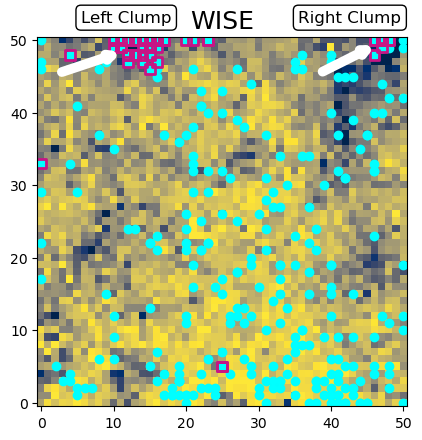

In [39]:
import numpy as np
import matplotlib.pyplot as plt

# Assuming necessary variables (AGN, fnAGN, etc.) are defined elsewhere

flagcon = AGN[:][5+5][conAGN] == 1
AGNf = np.array([fnAGN[flagcon], nuAGN[flagcon], ugAGN[flagcon], grAGN[flagcon], riAGN[flagcon], izAGN[flagcon], w12AGN[flagcon]])
AGNflag = AGNf.T
BMU_AGNflag = sm.bmu_ind_to_xy(sm.project_data(AGNflag))

xxAGNs, xyAGNs = np.zeros(len(BMU_AGNflag)), np.zeros(len(BMU_AGNflag))
k = 0
for i in BMU_AGNflag:
    xxAGNs[k] = i[0]
    xyAGNs[k] = i[1]
    k += 1

plt.title('WISE', fontsize=18)    
cf = plt.imshow(surakh(med_r), origin='lower', cmap='cividis', vmin=7.95, vmax=9.1)
plt.scatter(yAGN, xAGN, color='aqua', marker='o', alpha=1)  # point!!! plt.imshow sees the array like a matrix!
plt.scatter(xyAGNs, xxAGNs, marker='s', edgecolor='mediumvioletred', facecolors='none', s=50, linewidth=2)

# Adding arrows pointing to the top-right and top-left corners
plt.annotate('', xy=(plt.xlim()[1] - 4, plt.ylim()[1] - 1), xytext=(plt.xlim()[1] - 12, plt.ylim()[1] - 5),
             arrowprops=dict(facecolor='red', edgecolor='white', arrowstyle='->', lw=7))
plt.annotate('', xy=(plt.xlim()[0] + 12, plt.ylim()[1] - 2), xytext=(plt.xlim()[0] + 3, plt.ylim()[1] - 5),
             arrowprops=dict(facecolor='red', edgecolor='white', arrowstyle='->', lw=7))

# Adding labeled boxes next to each arrow
plt.text(plt.xlim()[1] - 15, plt.ylim()[1] + 2, 'Right Clump', fontsize=12, bbox=dict(facecolor='white', edgecolor='black', boxstyle='round,pad=0.3'))
plt.text(plt.xlim()[0] + 6, plt.ylim()[1] + 2, 'Left Clump', fontsize=12, bbox=dict(facecolor='white', edgecolor='black', boxstyle='round,pad=0.3'))

plt.savefig("WISEarrow.png", dpi=300)
plt.show()


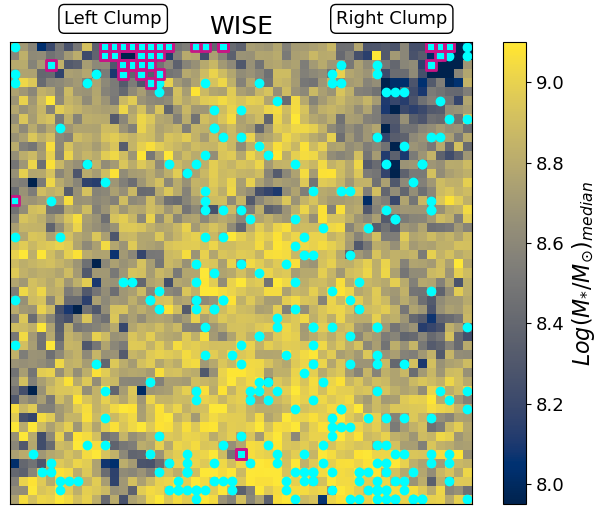

In [40]:
import numpy as np
import matplotlib.pyplot as plt

# Assuming necessary variables (AGN, fnAGN, etc.) are defined elsewhere

flagcon = AGN[:][5+5][conAGN] == 1
AGNf = np.array([fnAGN[flagcon], nuAGN[flagcon], ugAGN[flagcon], grAGN[flagcon],
                 riAGN[flagcon], izAGN[flagcon], w12AGN[flagcon]])
AGNflag = AGNf.T
BMU_AGNflag = sm.bmu_ind_to_xy(sm.project_data(AGNflag))

xxAGNs, xyAGNs = np.zeros(len(BMU_AGNflag)), np.zeros(len(BMU_AGNflag))
for k, i in enumerate(BMU_AGNflag):
    xxAGNs[k], xyAGNs[k] = i[0], i[1]

plt.figure(figsize=(8, 6))
plt.title('WISE', fontsize=18)    

# Background mass distribution
cf = plt.imshow(surakh(med_r), origin='lower', cmap='cividis', vmin=7.95, vmax=9.1)

# Colorbar with larger font
cbar = plt.colorbar(cf)
cbar.set_label(r'$Log(M_{*}/M_{\odot})_{median}$', fontsize=16)
cbar.ax.tick_params(labelsize=13)

# REMOVE x and y ticks
plt.xticks([])
plt.yticks([])

# Scatter AGNs
plt.scatter(yAGN, xAGN, color='aqua', marker='o', alpha=1, label="All AGNs")  
plt.scatter(xyAGNs, xxAGNs, marker='s', edgecolor='mediumvioletred', facecolors='none', s=50, linewidth=2, label="WISE-selected AGNs")

# Arrows
#plt.annotate('', xy=(plt.xlim()[1] - 4, plt.ylim()[1] - 1), xytext=(plt.xlim()[1] - 12, plt.ylim()[1] - 5),
             #arrowprops=dict(facecolor='red', edgecolor='white', arrowstyle='->', lw=7))
#plt.annotate('', xy=(plt.xlim()[0] + 12, plt.ylim()[1] - 2), xytext=(plt.xlim()[0] + 3, plt.ylim()[1] - 5),
             #arrowprops=dict(facecolor='red', edgecolor='white', arrowstyle='->', lw=7))

# Labels near arrows
plt.text(plt.xlim()[1] - 15, plt.ylim()[1] + 2, 'Right Clump', fontsize=13,
         bbox=dict(facecolor='white', edgecolor='black', boxstyle='round,pad=0.3'))
plt.text(plt.xlim()[0] + 6, plt.ylim()[1] + 2, 'Left Clump', fontsize=13,
         bbox=dict(facecolor='white', edgecolor='black', boxstyle='round,pad=0.3'))

plt.savefig("WISEarrow_colorbar_noticks.png", dpi=300)
plt.show()


/var/folders/5z/mxcl46zj3p76_rgxd645pmzr0000gn/T/ipykernel_85598/76961154.py:52: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


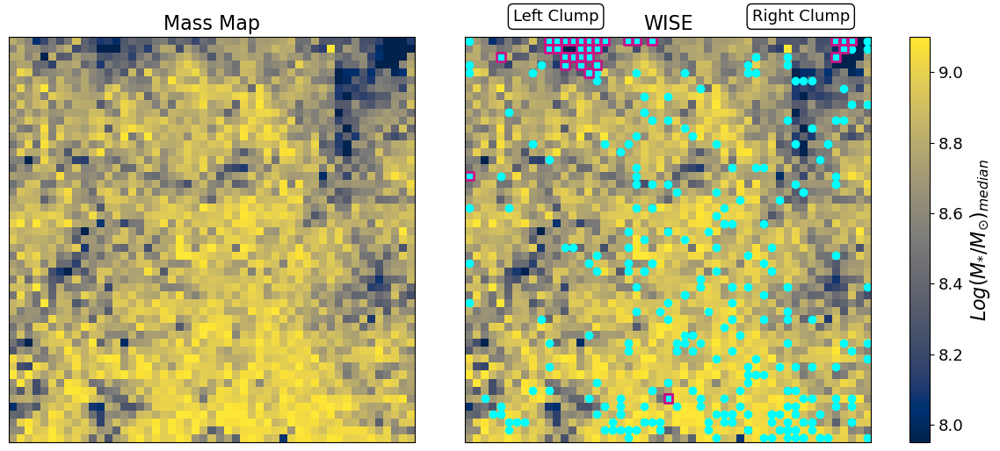

In [44]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec

# Assuming necessary variables (AGN, fnAGN, etc.) are defined elsewhere

# --- Shared pre-processing ---
flagcon = AGN[:][5+5][conAGN] == 1
AGNf = np.array([fnAGN[flagcon], nuAGN[flagcon], ugAGN[flagcon], grAGN[flagcon],
                 riAGN[flagcon], izAGN[flagcon], w12AGN[flagcon]])
AGNflag = AGNf.T
BMU_AGNflag = sm.bmu_ind_to_xy(sm.project_data(AGNflag))

xxAGNs, xyAGNs = np.zeros(len(BMU_AGNflag)), np.zeros(len(BMU_AGNflag))
for k, i in enumerate(BMU_AGNflag):
    xxAGNs[k], xyAGNs[k] = i[0], i[1]

# --- Make the figure with 2 subplots ---
fig = plt.figure(figsize=(14, 6))
gs = gridspec.GridSpec(1, 2, width_ratios=[1, 1], wspace=0.1)

# LEFT PLOT (second code: background only)
ax1 = plt.subplot(gs[0])
im = ax1.imshow(surakh(med_r), origin='lower', cmap='cividis', vmin=7.95, vmax=9.1)
ax1.set_title('Mass Map', fontsize=16)
ax1.set_xticks([])
ax1.set_yticks([])

# RIGHT PLOT (first code: background + scatter + labels)
ax2 = plt.subplot(gs[1])
cf = ax2.imshow(surakh(med_r), origin='lower', cmap='cividis', vmin=7.95, vmax=9.1)
ax2.set_title('WISE', fontsize=16)
ax2.set_xticks([])
ax2.set_yticks([])

# Scatter AGNs
ax2.scatter(yAGN, xAGN, color='aqua', marker='o', alpha=1, label="All AGNs")
ax2.scatter(xyAGNs, xxAGNs, marker='s', edgecolor='mediumvioletred', 
            facecolors='none', s=50, linewidth=2, label="WISE-selected AGNs")

# Labels near arrows
ax2.text(ax2.get_xlim()[1] - 15, ax2.get_ylim()[1] + 2, 'Right Clump', fontsize=13,
         bbox=dict(facecolor='white', edgecolor='black', boxstyle='round,pad=0.3'))
ax2.text(ax2.get_xlim()[0] + 6, ax2.get_ylim()[1] + 2, 'Left Clump', fontsize=13,
         bbox=dict(facecolor='white', edgecolor='black', boxstyle='round,pad=0.3'))

# Add shared colorbar on the right
cbar = fig.colorbar(im, ax=[ax1, ax2], fraction=0.046, pad=0.04)
cbar.set_label(r'$Log(M_{*}/M_{\odot})_{median}$', fontsize=16)
cbar.ax.tick_params(labelsize=13)

plt.tight_layout()
plt.savefig("WISE_combined.png", dpi=300)
plt.show()


78
139
171
153
8
83
X WISE = [14. 13. 46. 12. 47. 10. 16. 48. 15. 13. 14. 15. 25. 14. 47. 47. 14. 15.
 11. 10. 14. 47. 46. 13. 10.  4. 13. 17. 15. 20. 47. 25. 15. 47. 10. 12.
 47. 14. 14. 11. 48. 16. 14. 46. 23. 16. 15. 11. 13. 13. 16. 46. 47. 47.
 47. 47. 14. 12. 47. 23. 46. 47. 21. 13. 15. 46. 16. 11. 13. 10. 16. 11.
 13. 15. 12. 12. 16. 15.  0. 17. 13. 47. 47.]
Y WISE = [48. 50. 50. 47. 50. 50. 49. 50. 48. 50. 49. 50.  5. 50. 50. 50. 47. 49.
 49. 49. 50. 50. 50. 50. 50. 48. 50. 50. 50. 50. 50.  5. 46. 50. 50. 50.
 50. 50. 50. 49. 50. 50. 50. 50. 50. 50. 50. 49. 50. 50. 47. 50. 50. 50.
 49. 50. 50. 48. 50. 50. 50. 50. 50. 50. 49. 48. 50. 50. 50. 49. 50. 49.
 48. 49. 50. 48. 50. 49. 33. 50. 48. 50. 50.]
32
89
starbursts = 12
X positions of starbursts = [47. 47. 46. 47. 47. 47. 12. 47. 47. 47. 46. 47.]
Y positions of starbursts = [49. 50. 50. 50. 50. 50. 50. 50. 50. 50. 50. 50.]


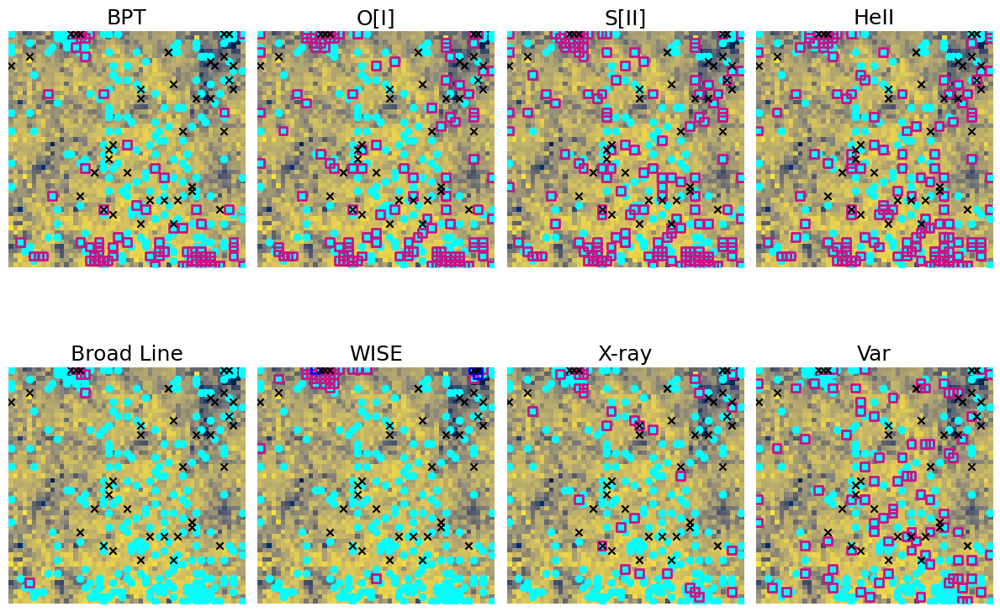

In [391]:
agnflagnames=['BPT','O[I]','S[II]','HeII','Broad Line','WISE','X-ray', 'Var']
plt.figure(figsize=(12,9))
for fla in range(0,8):
    try:
        flagcon = AGN[:][5+fla][conAGN]== 1
        AGNf = np.array([fnAGN[flagcon], nuAGN[flagcon], ugAGN[flagcon], grAGN[flagcon], riAGN[flagcon], izAGN[flagcon], w12AGN[flagcon]])
        AGNflag = AGNf.T
        BMU_AGNflag = sm.bmu_ind_to_xy(sm.project_data(AGNflag))

        xxAGNs,xyAGNs=np.zeros(len(BMU_AGNflag)),np.zeros(len(BMU_AGNflag))
        k=0
        for i in BMU_AGNflag:
            xxAGNs[k]=i[0]
            xyAGNs[k]=i[1]
            k+=1
        plt.subplot(2,4,fla+1)
        plt.title(agnflagnames[fla],fontsize=18)
        cf=plt.imshow(surakh(med_r),origin='lower',cmap='cividis',vmin = 7.7,vmax = max(massclean))
    
        if(fla == 5):
            plt.scatter(yAGN, xAGN,color='aqua',marker='o',alpha=1) #point!!! plt.imshow sees the array like a matrix! it is not the same as how we fill the array. so X and Y are reversed.
            plt.scatter(xyAGNs, xxAGNs,marker='s', edgecolor='mediumvioletred', facecolors='none',s=50,linewidth=2)
            plt.scatter(ys, xs,marker='s', edgecolor='blue', facecolors='none',s=50,linewidth=2)
            plt.scatter(yc, xc,color='black',marker='x')
            print(len(xyAGNs))
            plt.axis('off')
            print('X WISE =',xyAGNs)
            print('Y WISE =',xxAGNs)
        else:    
            plt.scatter(yAGN, xAGN,color='aqua',marker='o',alpha=1) #point!!! plt.imshow sees the array like a matrix! it is not the same as how we fill the array. so X and Y are reversed.
            plt.scatter(xyAGNs, xxAGNs,marker='s', edgecolor='mediumvioletred', facecolors='none',s=50,linewidth=2)
            print(len(xyAGNs))
            plt.scatter(yc, xc,color='black',marker='x')
            plt.axis('off')
    except:
        continue
plt.tight_layout()
plt.savefig("dwarfagnc", dpi = 300)
print('starbursts =', len(xs))
print('X positions of starbursts =', ys)
print('Y positions of starbursts =', xs)

In [296]:
#getting RA and Dec of tagerts within WISE right and left clump!
#got better idea!find mass instead and find the target in the google sheet color code it there!!
right = (x == 45)&(y == 15)
print(massclean[right])

[8.20454278 8.47729193 7.02586304 8.54675763 8.59018354 8.69628997
 9.09830658 8.9352199  8.7410512  8.41024449]


In [297]:
OnlyWISE = (AGN[:][5+5][conAGN]== 1)&(AGN[:][5+0][conAGN]== -99)&(AGN[:][5+1][conAGN]== -99)&(AGN[:][5+2][conAGN]== -99)&(AGN[:][5+3][conAGN]== -99)&(AGN[:][5+4][conAGN]== -99)&(AGN[:][5+6][conAGN]== -99)&(AGN[:][5+7][conAGN]== -99)
#print(OnlyWISE)
#RA of only WISE AGNs
print(AGN[:][0][conAGN][OnlyWISE])
#Dec of only WISE AGNs
print(AGN[:][1][conAGN][OnlyWISE])

#finding OIII/Hb and NII/Ha ratios for BPT
O3w = np.array(AGN[:][41][conAGN][OnlyWISE])
Hbw = np.array(AGN[:][39][conAGN][OnlyWISE])
NIIw = np.array(AGN[:][45][conAGN][OnlyWISE])
Haw = np.array(AGN[:][37][conAGN][OnlyWISE])
conbptw = (Hbw > 0) & (Haw > 0)
O3Hbw = np.array(O3w[conbptw]/Hbw[conbptw])
N2Haw = np.array(NIIw[conbptw]/Haw[conbptw])
print(len(O3Hbw))

[205.4233989  227.392403   185.8189058  176.4176899  136.3795142
 263.7552145  236.4314768  187.0950757  192.0560257  170.1686738
 133.1405738   14.76712747 156.1219276  117.7872276  215.9286296
 174.2130694  139.1707659  161.2408402  120.3488415  130.6524438
 180.3429521  202.220649    34.72045251 195.9768556  146.8422565
 130.1246614  129.1478618  228.0535623  245.4690625  134.5264232
 157.5973119  173.2389394  131.365003  ]
[35.03723003 37.52951706  4.83614593 -0.57080154  3.59179153 57.05243448
  8.9670402  20.34546577 43.95097538 67.77895379 13.84125406  1.00120706
  5.41415855 22.7409444  22.95799481  7.67368853 18.46885531  3.88699566
 39.88956038 10.55386729  2.18566444 15.99287407 -9.20523088 37.23383928
  0.74081385 47.1195566  22.29456528 47.27519788 15.31555475 49.82994731
 28.34974463 31.47551409 53.14808273]
33


In [298]:
WISE = (AGN[:][5+5][conAGN]== 1)
#RA of totWISE+ AGNs
print(AGN[:][0][conAGN][WISE])
#Dec of totWISE+ AGNs
print(AGN[:][1][conAGN][WISE])

#finding OIII/Hb and NII/Ha ratios for BPT
O3 = np.array(AGN[:][41][conAGN][WISE])
Hb = np.array(AGN[:][39][conAGN][WISE])
NII = np.array(AGN[:][45][conAGN][WISE])
Ha = np.array(AGN[:][37][conAGN][WISE])
conbpt = (Hb > 0) & (Ha > 0)
O3Hb = np.array(O3[conbpt]/Hb[conbpt])
N2Ha = np.array(NII[conbpt]/Ha[conbpt])
print(len(O3Hb))
#In the end after the training, There is 7 overlap between wise selected AGNs and BPT selected AGNs and that is a reliable result based on our training, the one includes WISE colors have separated BPT and WISE AGNs completely!

[138.6508989  205.4233989  125.8951975  202.4246972  227.392403
 149.7473032  231.655695   185.8189058  119.174191   182.5347904
 176.4176899  203.1900893  175.9983133  159.8766862  136.3795142
 263.7552145  129.5063851  186.4536172  138.7713825   12.62068046
 136.5573203  236.4314768  187.0950757  192.0560257  170.1686738
 133.1405738  157.4303731  314.0245729   14.76712747 240.7569725
 156.1219276  117.7872276  174.1779713  215.9286296  206.11397
 174.2130694  139.1707659  220.0529349  240.3998368  202.3851402
 161.2408402  120.3488415  142.9870569  130.6524438  236.0180561
 255.876544   148.5756446  166.9029528  180.3429521  225.7934517
 171.5767484  161.3350501  236.9541508  202.220649    34.72045251
 195.9768556  146.8422565  345.4487577  130.1246614  129.1478618
 228.0535623  245.4690625  159.8742371  249.9052283  134.5264232
 214.5072844  126.1980006  345.7632937  182.6358088  157.5973119
 125.6680175  244.848518   198.0259727  179.146734   173.2389394
 131.1781501  119.1751815 

/var/folders/5z/mxcl46zj3p76_rgxd645pmzr0000gn/T/ipykernel_3971/2109458678.py:6: RuntimeWarning: invalid value encountered in log10
  N2Ha1 = np.log10(N2Ha)
/var/folders/5z/mxcl46zj3p76_rgxd645pmzr0000gn/T/ipykernel_3971/2109458678.py:7: RuntimeWarning: invalid value encountered in log10
  O3Hb1 = np.log10(O3Hb)


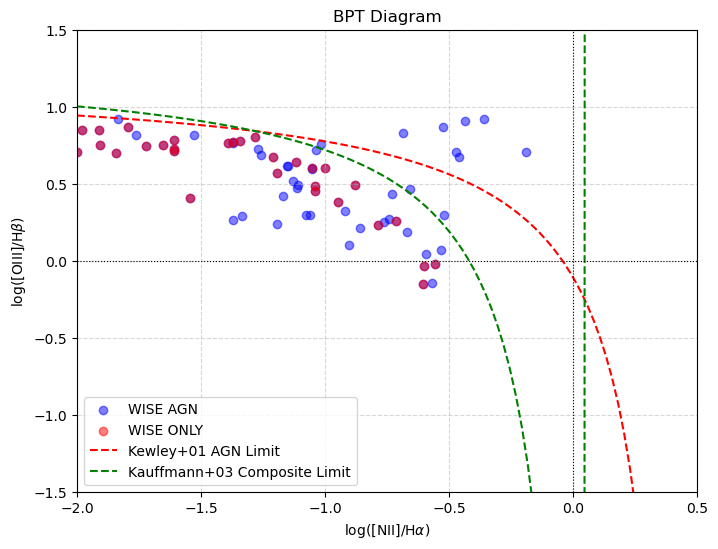

In [299]:
#plotting totWISE+ AGNs on BPT diagram
import numpy as np
import matplotlib.pyplot as plt

# Sample data (replace these with your actual arrays)
N2Ha1 = np.log10(N2Ha)
O3Hb1 = np.log10(O3Hb)

N2Haw1 = np.log10(N2Haw)
O3Hbw1 = np.log10(O3Hbw)
# Define the separator lines:
# Kewley et al. (2001) AGN boundary
def kewley_line(x):
    return 0.61 / (x - 0.47) + 1.19

# Kauffmann et al. (2003) empirical star-forming boundary
def kauffmann_line(x):
    return 0.61 / (x - 0.05) + 1.3

# Generate x values for the boundary lines
x_vals = np.linspace(-2, 0.4, 100)
kewley_vals = kewley_line(x_vals)
kauffmann_vals = kauffmann_line(x_vals)

# Plot the BPT diagram
plt.figure(figsize=(8, 6))
plt.scatter(N2Ha1, O3Hb1, color='blue', alpha=0.5, label='WISE AGN')
plt.scatter(N2Haw1, O3Hbw1, color='red', alpha=0.5, label='WISE ONLY')

# Plot separator lines
plt.plot(x_vals, kewley_vals, 'r--', label="Kewley+01 AGN Limit")
plt.plot(x_vals, kauffmann_vals, 'g--', label="Kauffmann+03 Composite Limit")

# Labels and legend
plt.xlabel(r"log([NII]/H$\alpha$)")
plt.ylabel(r"log([OIII]/H$\beta$)")
plt.title("BPT Diagram")
plt.axhline(0, color='k', linewidth=0.8, linestyle=":")
plt.axvline(0, color='k', linewidth=0.8, linestyle=":")
plt.xlim(-2, 0.5)
plt.ylim(-1.5, 1.5)
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)

plt.savefig("BPT", dpi = 300)
plt.show()

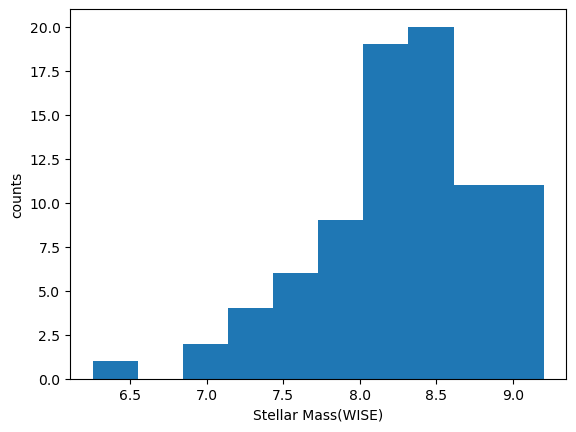

In [300]:
flagcon1 = AGN[:][10][conAGN]== 1
plt.hist(massAGNclean[flagcon1])
plt.xlabel("Stellar Mass(WISE)")
plt.ylabel("counts")
plt.savefig("MW", dpi = 300)

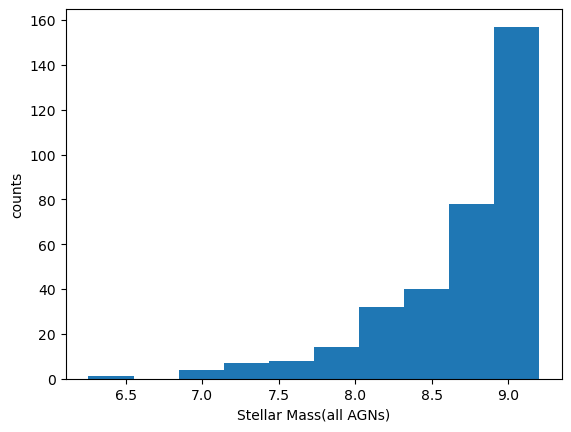

In [301]:
plt.hist(massAGNclean)
plt.xlabel("Stellar Mass(all AGNs)")
plt.ylabel("counts")
plt.savefig("MA", dpi = 300)

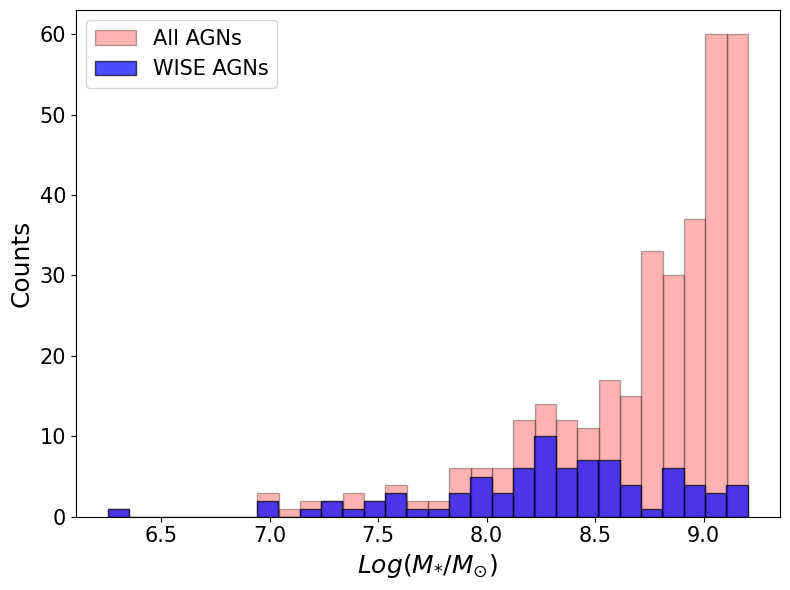

In [307]:
import matplotlib.pyplot as plt

# Define binning for consistency
bins = 30  # Adjust as needed

# Create figure
plt.figure(figsize=(8, 6))

# Plot histogram for all AGNs (background histogram)
plt.hist(massAGNclean, bins=bins, color='red', alpha=0.3, edgecolor='black', label="All AGNs")

# Plot histogram for WISE targets (foreground histogram)
plt.hist(massAGNclean[flagcon1], bins=bins, color='blue', alpha=0.7, edgecolor='black', label="WISE AGNs")

# Labels and legend
plt.xlabel(r'$Log(M_{*}/M_{\odot})$', fontsize=18)
plt.ylabel("Counts", fontsize=18)
plt.xticks(fontsize=15)  # Increase x-axis numbers
plt.yticks(fontsize=15)  # Increase y-axis numbers
plt.legend(fontsize=15)

# Save and show the figure
plt.tight_layout()
plt.savefig("Mass_Comparisonn.png", dpi=300)
plt.show()


In [278]:
OnlyWISE = (AGN[:][5+5][conAGN]== 1)&(AGN[:][5+0][conAGN]== -99)&(AGN[:][5+1][conAGN]== -99)&(AGN[:][5+2][conAGN]== -99)&(AGN[:][5+3][conAGN]== -99)&(AGN[:][5+4][conAGN]== -99)&(AGN[:][5+6][conAGN]== -99)&(AGN[:][5+7][conAGN]== -99)

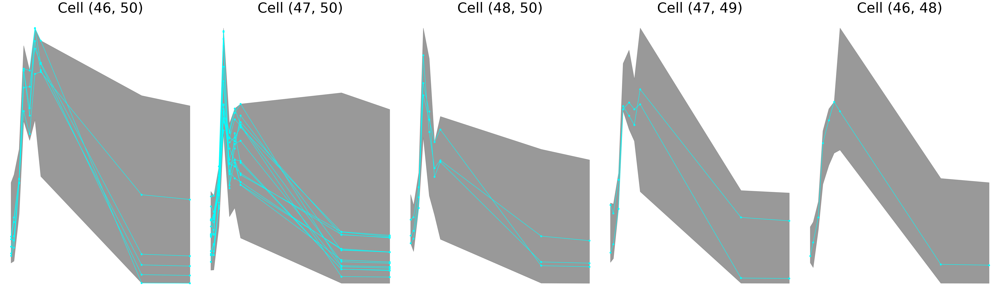

In [292]:
import numpy as np
import matplotlib.pyplot as plt

# Define the specific SOM cells for which we want to plot the SEDs
selected_cells = [(46, 50), (47, 50), (48, 50), (47, 49), (46, 48)]

def plot_SED_GDN(a, b):
    # Define the wavelengths
    wavelength = np.array([153, 227, 355, 468, 616, 748, 893, 3400, 4600])

    # Find galaxies in the specified SOM cell (a, b)
    cell = (x == b) & (y == a)

    # Initialize a list to store flux arrays for this cell
    flux_lists = []
    
    for i in range(len(cell)):
        if cell[i]:
            flux = np.array([f_clean[i], n_clean[i], u_clean[i], g_clean[i], 
                             r_clean[i], i_clean[i], z_clean[i], w1_clean[i], w2_clean[i]])
            flux_lists.append(flux / np.mean(flux))  # Normalize flux and add to the list

    # If there are no sources in the cell, skip plotting
    if not flux_lists:
        plt.axis('off')
        return

    # Convert to a numpy array
    allflux = np.array(flux_lists)

    # Compute the max, min, and mean flux in the cell
    flux_max = np.amax(allflux, axis=0)
    flux_min = np.amin(allflux, axis=0)
    flux_mean = np.mean(allflux, axis=0)

    # Plot SED shading (range of values)
    plt.fill_between(wavelength, flux_min, flux_max, color='gray', alpha=0.8)

    # Find AGNs in the same cell and plot their SEDs
    cell_AGN = (xAGN == b) & (yAGN == a)

    for i in range(len(cell_AGN)):
        if cell_AGN[i]:
            flux_AGN = np.array([fAGN_clean[i], nAGN_clean[i], uAGN_clean[i], gAGN_clean[i], 
                                 rAGN_clean[i], iAGN_clean[i], zAGN_clean[i], w1AGN_clean[i], w2AGN_clean[i]])
            plt.plot(wavelength, flux_AGN / np.mean(flux_AGN), marker='o', linestyle='-', color='cyan', alpha=1)

    # Hide axis labels for a cleaner visualization
    plt.axis('off')

# Number of selected cells
num_cells = len(selected_cells)
plt.figure(figsize=(50, 3 * num_cells))  # Adjust figure size dynamically

# Loop through only the selected cells
for idx, (i, j) in enumerate(selected_cells):
    plt.subplot(1, num_cells, idx + 1)  # Create subplots for selected cells
    try:
        plot_SED_GDN(i, j)  # Call function for each selected cell
        plt.title(f"Cell ({i}, {j})", fontsize=50)
    except Exception as e:
        print(f"Error in cell ({i}, {j}): {e}")
        plt.axis('off')
        continue

plt.tight_layout()
plt.savefig("Selected_SOM_SEDs.png", dpi=300)
plt.show()


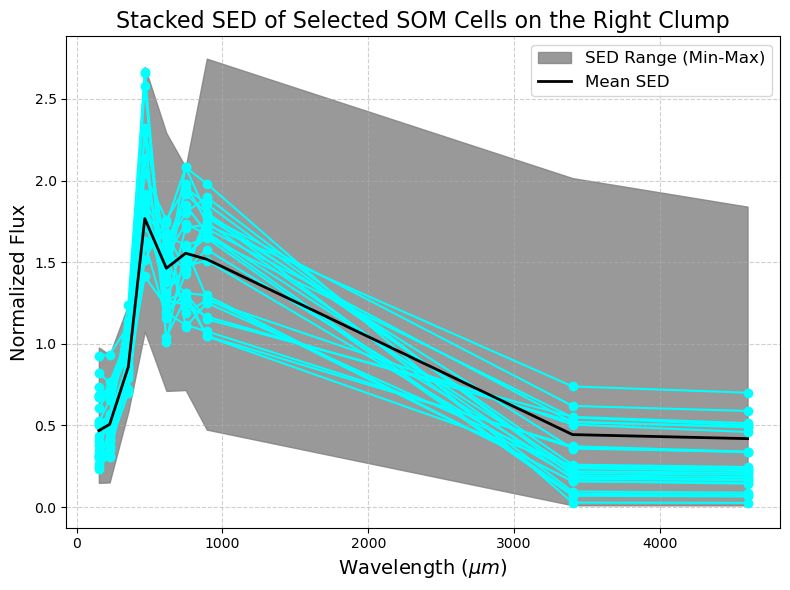

In [423]:
import numpy as np
import matplotlib.pyplot as plt

# Define the new selected SOM cells
selected_cells = [(46, 50), (47, 50), (48, 50), (47, 49), (46, 48)]

# Define the wavelengths
wavelength = np.array([153, 227, 355, 468, 616, 748, 893, 3400, 4600])

# Initialize lists to store stacked fluxes
all_fluxes = []
all_AGN_fluxes = []

# Loop through selected SOM cells and extract SEDs
for (a, b) in selected_cells:
    cell = (x == b) & (y == a)

    for i in range(len(cell)):
        if cell[i]:  # If galaxy exists in the cell
            flux = np.array([f_clean[i], n_clean[i], u_clean[i], g_clean[i], 
                             r_clean[i], i_clean[i], z_clean[i], w1_clean[i], w2_clean[i]])
            all_fluxes.append(flux / np.mean(flux))  # Normalize and append flux

    # Find AGN SEDs in the same cell
    cell_AGN = (xAGN == b) & (yAGN == a)
    for i in range(len(cell_AGN)):
        if cell_AGN[i]:  # If AGN exists in the cell
            flux_AGN = np.array([fAGN_clean[i], nAGN_clean[i], uAGN_clean[i], gAGN_clean[i], 
                                 rAGN_clean[i], iAGN_clean[i], zAGN_clean[i], w1AGN_clean[i], w2AGN_clean[i]])
            all_AGN_fluxes.append(flux_AGN / np.mean(flux_AGN))  # Normalize and append flux

# Convert to numpy arrays
all_fluxes = np.array(all_fluxes)
all_AGN_fluxes = np.array(all_AGN_fluxes)

# Compute the max, min, and mean flux across all selected cells
flux_max = np.amax(all_fluxes, axis=0)
flux_min = np.amin(all_fluxes, axis=0)
flux_mean = np.mean(all_fluxes, axis=0)

# Plot SED
plt.figure(figsize=(8, 6))
plt.fill_between(wavelength, flux_min, flux_max, color='gray', alpha=0.8, label="SED Range (Min-Max)")


# Overlay AGN SEDs in cyan
for flux_AGN in all_AGN_fluxes:
    plt.plot(wavelength, flux_AGN, marker='o', linestyle='-', color='cyan', alpha=1)
plt.plot(wavelength, flux_mean, linestyle='-', color='black', linewidth=2, label="Mean SED")
# Labels and title
plt.xlabel(r'Wavelength ($\mu m$)', fontsize=14)
plt.ylabel(r'Normalized Flux', fontsize=14)
plt.title('Stacked SED of Selected SOM Cells on the Right Clump', fontsize=16)
plt.legend(fontsize=12)
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()

# Save and show the plot
plt.savefig("SED_Right.png", dpi=300)
plt.show()


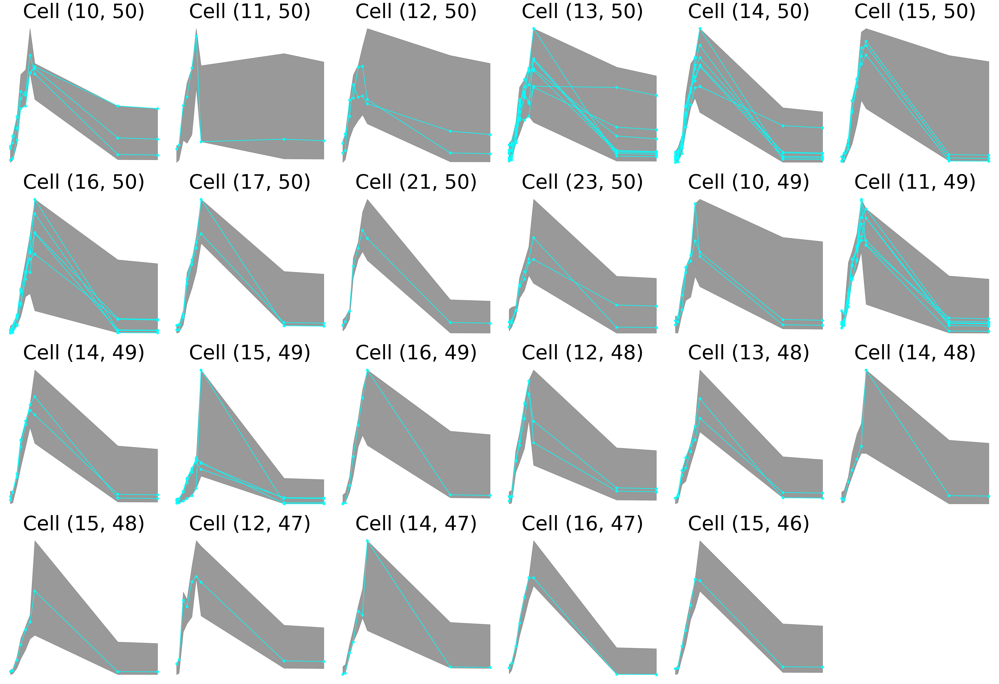

In [299]:
import numpy as np
import matplotlib.pyplot as plt

# Define the specific SOM cells to plot
selected_cells = [
    (10, 50), (11, 50), (12, 50), (13, 50), (14, 50), (15, 50), (16, 50), (17, 50), (21, 50), (23, 50),
    (10, 49), (11, 49), (14, 49), (15, 49), (16, 49),
    (12, 48), (13, 48), (14, 48), (15, 48),
    (12, 47), (14, 47), (16, 47),
    (15, 46)
]

def plot_SED_GDN(a, b):
    # Define the wavelengths
    wavelength = np.array([153, 227, 355, 468, 616, 748, 893, 3400, 4600])

    # Find galaxies in the given SOM cell (a, b)
    cell = (x == b) & (y == a)

    # Initialize a list to store flux arrays for this cell
    flux_lists = []
    
    for i in range(len(cell)):
        if cell[i]:
            flux = np.array([f_clean[i], n_clean[i], u_clean[i], g_clean[i], 
                             r_clean[i], i_clean[i], z_clean[i], w1_clean[i], w2_clean[i]])
            flux_lists.append(flux / np.mean(flux))  # Normalize flux and add to the list

    # If there are no sources in the cell, skip plotting
    if not flux_lists:
        plt.axis('off')
        return

    # Convert to a numpy array
    allflux = np.array(flux_lists)

    # Compute the max, min, and mean flux in the cell
    flux_max = np.amax(allflux, axis=0)
    flux_min = np.amin(allflux, axis=0)
    flux_mean = np.mean(allflux, axis=0)

    # Plot SED shading (range of values)
    plt.fill_between(wavelength, flux_min, flux_max, color='gray', alpha=0.8)

    # Find AGNs in the same cell and plot their SEDs
    cell_AGN = (xAGN == b) & (yAGN == a)

    for i in range(len(cell_AGN)):
        if cell_AGN[i]:
            flux_AGN = np.array([fAGN_clean[i], nAGN_clean[i], uAGN_clean[i], gAGN_clean[i], 
                                 rAGN_clean[i], iAGN_clean[i], zAGN_clean[i], w1AGN_clean[i], w2AGN_clean[i]])
            plt.plot(wavelength, flux_AGN / np.mean(flux_AGN), marker='o', linestyle='-', color='cyan', alpha=1)

    # Hide axis labels for a cleaner visualization
    plt.axis('off')

# Define subplot grid size (6 rows × 4 columns)
rows, cols = 4, 6
plt.figure(figsize=(35, 24))  # Adjust figure size for better visualization

# Loop through only the selected cells
for idx, (i, j) in enumerate(selected_cells):
    plt.subplot(rows, cols, idx + 1)  # Place each SED plot in a 6×4 layout
    try:
        plot_SED_GDN(i, j)  # Call function for each selected cell
        plt.title(f"Cell ({i}, {j})", fontsize=50)
    except Exception as e:
        print(f"Error in cell ({i}, {j}): {e}")
        plt.axis('off')
        continue

plt.tight_layout()
plt.savefig("Selected_SOM_SEDs_6x4.png", dpi=300)
plt.show()


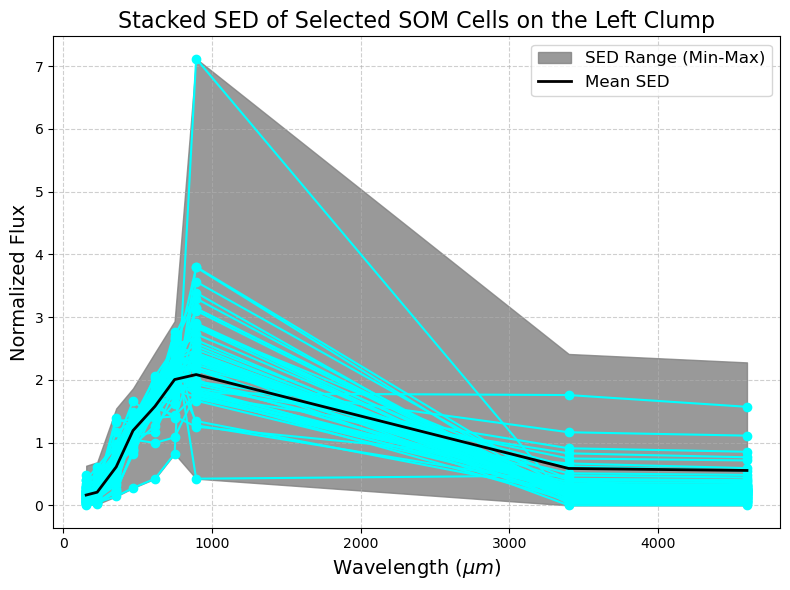

In [398]:
import numpy as np
import matplotlib.pyplot as plt

# Define the specific SOM cells to stack
selected_cells = [
    (10, 50), (11, 50), (12, 50), (13, 50), (14, 50), (15, 50), (16, 50), (17, 50), (21, 50), (23, 50),
    (10, 49), (11, 49), (14, 49), (15, 49), (16, 49),
    (12, 48), (13, 48), (14, 48), (15, 48),
    (12, 47), (14, 47), (16, 47),
    (15, 46)
]

# Define the wavelengths
wavelength = np.array([153, 227, 355, 468, 616, 748, 893, 3400, 4600])

# Initialize lists to store stacked fluxes
all_fluxes = []
all_AGN_fluxes = []

# Loop through selected SOM cells and extract SEDs
for (a, b) in selected_cells:
    cell = (x == b) & (y == a)

    for i in range(len(cell)):
        if cell[i]:  # If galaxy exists in the cell
            flux = np.array([f_clean[i], n_clean[i], u_clean[i], g_clean[i], 
                             r_clean[i], i_clean[i], z_clean[i], w1_clean[i], w2_clean[i]])
            all_fluxes.append(flux / np.mean(flux))  # Normalize and append flux

    # Find AGN SEDs in the same cell
    cell_AGN = (xAGN == b) & (yAGN == a)
    for i in range(len(cell_AGN)):
        if cell_AGN[i]:  # If AGN exists in the cell
            flux_AGN = np.array([fAGN_clean[i], nAGN_clean[i], uAGN_clean[i], gAGN_clean[i], 
                                 rAGN_clean[i], iAGN_clean[i], zAGN_clean[i], w1AGN_clean[i], w2AGN_clean[i]])
            all_AGN_fluxes.append(flux_AGN / np.mean(flux_AGN))  # Normalize and append flux

# Convert to numpy arrays
all_fluxes = np.array(all_fluxes)
all_AGN_fluxes = np.array(all_AGN_fluxes)

# Compute the max, min, and mean flux across all selected cells
flux_max = np.amax(all_fluxes, axis=0)
flux_min = np.amin(all_fluxes, axis=0)
flux_mean = np.mean(all_fluxes, axis=0)

# Plot SED
plt.figure(figsize=(8, 6))
plt.fill_between(wavelength, flux_min, flux_max, color='gray', alpha=0.8, label="SED Range (Min-Max)")


# Overlay AGN SEDs in cyan
for flux_AGN in all_AGN_fluxes:
    plt.plot(wavelength, flux_AGN, marker='o', linestyle='-', color='cyan', alpha=1)

plt.plot(wavelength, flux_mean, linestyle='-', color='black', linewidth=2, label="Mean SED")
# Labels and title
plt.xlabel(r'Wavelength ($\mu m$)', fontsize=14)
plt.ylabel(r'Normalized Flux', fontsize=14)
plt.title('Stacked SED of Selected SOM Cells on the Left Clump', fontsize=16)
plt.legend(fontsize=12)
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()

# Save and show the plot
plt.savefig("SED_Left.png", dpi=300)
plt.show()


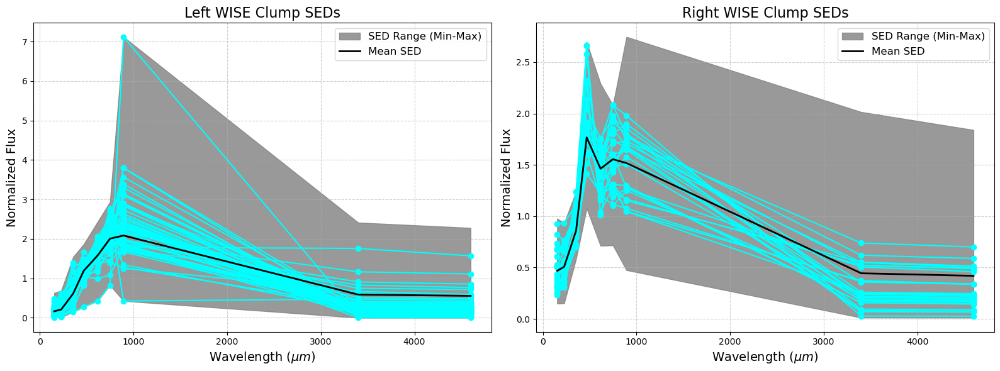

In [406]:
import numpy as np
import matplotlib.pyplot as plt

# Define wavelengths
wavelength = np.array([153, 227, 355, 468, 616, 748, 893, 3400, 4600])

# Define SOM cells for Left and Right Clumps
selected_cells_right = [(46, 50), (47, 50), (48, 50), (47, 49), (46, 48)]
selected_cells_left = [
    (10, 50), (11, 50), (12, 50), (13, 50), (14, 50), (15, 50), (16, 50), (17, 50), (21, 50), (23, 50),
    (10, 49), (11, 49), (14, 49), (15, 49), (16, 49),
    (12, 48), (13, 48), (14, 48), (15, 48),
    (12, 47), (14, 47), (16, 47),
    (15, 46)
]

def extract_sed_data(selected_cells):
    """Extracts SED data for the given SOM cells."""
    all_fluxes = []
    all_AGN_fluxes = []
    
    for (a, b) in selected_cells:
        cell = (x == b) & (y == a)

        for i in range(len(cell)):
            if cell[i]:  # If galaxy exists in the cell
                flux = np.array([f_clean[i], n_clean[i], u_clean[i], g_clean[i], 
                                 r_clean[i], i_clean[i], z_clean[i], w1_clean[i], w2_clean[i]])
                all_fluxes.append(flux / np.mean(flux))  # Normalize and append flux

        # Find AGN SEDs in the same cell
        cell_AGN = (xAGN == b) & (yAGN == a)
        for i in range(len(cell_AGN)):
            if cell_AGN[i]:  # If AGN exists in the cell
                flux_AGN = np.array([fAGN_clean[i], nAGN_clean[i], uAGN_clean[i], gAGN_clean[i], 
                                     rAGN_clean[i], iAGN_clean[i], zAGN_clean[i], w1AGN_clean[i], w2AGN_clean[i]])
                all_AGN_fluxes.append(flux_AGN / np.mean(flux_AGN))  # Normalize and append flux

    return np.array(all_fluxes), np.array(all_AGN_fluxes)

# Extract data for left and right clumps
all_fluxes_right, all_AGN_fluxes_right = extract_sed_data(selected_cells_right)
all_fluxes_left, all_AGN_fluxes_left = extract_sed_data(selected_cells_left)

# Compute stats for both groups
flux_max_right = np.amax(all_fluxes_right, axis=0)
flux_min_right = np.amin(all_fluxes_right, axis=0)
flux_mean_right = np.mean(all_fluxes_right, axis=0)

flux_max_left = np.amax(all_fluxes_left, axis=0)
flux_min_left = np.amin(all_fluxes_left, axis=0)
flux_mean_left = np.mean(all_fluxes_left, axis=0)

# Create side-by-side plots
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Plot Right Clump
axes[1].fill_between(wavelength, flux_min_right, flux_max_right, color='gray', alpha=0.8, label="SED Range (Min-Max)")
for flux_AGN in all_AGN_fluxes_right:
    axes[1].plot(wavelength, flux_AGN, marker='o', linestyle='-', color='cyan', alpha=1)
axes[1].plot(wavelength, flux_mean_right, linestyle='-', color='black', linewidth=2, label="Mean SED")
axes[1].set_xlabel(r'Wavelength ($\mu m$)', fontsize=14)
axes[1].set_ylabel(r'Normalized Flux', fontsize=14)
axes[1].set_title('Right WISE Clump SEDs', fontsize=16)
axes[1].grid(True, linestyle='--', alpha=0.6)
axes[1].legend(fontsize=12)

# Plot Left Clump
axes[0].fill_between(wavelength, flux_min_left, flux_max_left, color='gray', alpha=0.8, label="SED Range (Min-Max)")
for flux_AGN in all_AGN_fluxes_left:
    axes[0].plot(wavelength, flux_AGN, marker='o', linestyle='-', color='cyan', alpha=1)
axes[0].plot(wavelength, flux_mean_left, linestyle='-', color='black', linewidth=2, label="Mean SED")
axes[0].set_xlabel(r'Wavelength ($\mu m$)', fontsize=14)
axes[0].set_ylabel(r'Normalized Flux', fontsize=14)
axes[0].set_title('Left WISE Clump SEDs', fontsize=16)
axes[0].grid(True, linestyle='--', alpha=0.6)
axes[0].legend(fontsize=12)

# Adjust layout and save
plt.tight_layout()
plt.savefig("SED_Left_vs_Right.png", dpi=300)
plt.show()


In [283]:
import numpy as np
import matplotlib.pyplot as plt

def plot_SED_GDN(a, b):
    # Define the wavelengths
    wavelength = np.array([153, 227, 355, 468, 616, 748, 893, 3400, 4600])

    # Find galaxies in the given SOM cell (a, b)
    cell = (x == b) & (y == a)

    # Initialize a list to store flux arrays for this cell
    flux_lists = []
    
    for i in range(len(cell)):
        if cell[i]:
            flux = np.array([f_clean[i], n_clean[i], u_clean[i], g_clean[i], 
                             r_clean[i], i_clean[i], z_clean[i], w1_clean[i], w2_clean[i]])
            flux_lists.append(flux / np.mean(flux))  # Normalize flux and add to the list

    # If there are no sources in the cell, skip plotting
    if not flux_lists:
        plt.axis('off')
        return

    # Convert to a numpy array
    allflux = np.array(flux_lists)

    # Compute the max, min, and mean flux in the cell
    flux_max = np.amax(allflux, axis=0)
    flux_min = np.amin(allflux, axis=0)
    flux_mean = np.mean(allflux, axis=0)

    # Plot SED shading (range of values)
    plt.fill_between(wavelength, flux_min, flux_max, color='gray', alpha=0.3)

    # Find AGNs in the same cell and plot their SEDs
    cell_AGN = (xAGN == b) & (yAGN == a)

    for i in range(len(cell_AGN)):
        if cell_AGN[i]:
            flux_AGN = np.array([fAGN_clean[i], nAGN_clean[i], uAGN_clean[i], gAGN_clean[i], 
                                 rAGN_clean[i], iAGN_clean[i], zAGN_clean[i], w1AGN_clean[i], w2AGN_clean[i]])
            plt.plot(wavelength, flux_AGN / np.mean(flux_AGN), marker='o', linestyle='-', color='cyan', alpha=0.5)

    # Hide axis labels for a cleaner visualization
    plt.axis('off')

# Define the grid size (51×51)
gridsize = 51  
plt.figure(figsize=(100, 100))  # Adjust the figure size for better visualization

# Loop through each SOM cell individually
for i in range(gridsize):  # No more stepping in 3x3 blocks
    for j in range(gridsize):
        plt.subplot(gridsize, gridsize, i * gridsize + j + 1)  # Individual subplot per cell
        try:
            plot_SED_GDN(j, 51 - i - 1)  # Adjust indices to match the original plotting convention
        except Exception as e:
            print(f"Error in cell ({j}, {51 - i - 1}): {e}")
            plt.axis('off')
            continue

plt.tight_layout()
plt.savefig("SOM_SED_grid.png", dpi=300)
plt.show()


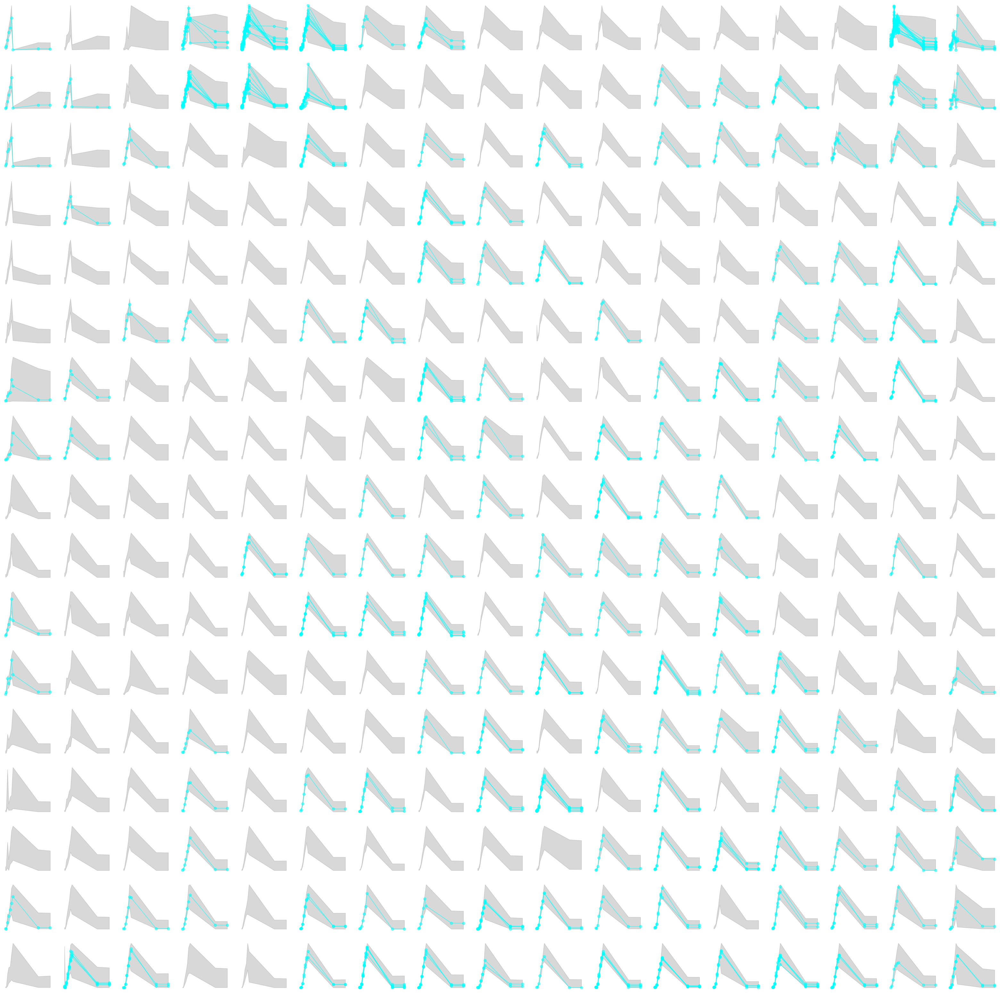

In [284]:
import numpy as np
import matplotlib.pyplot as plt

def plot_SED_GDN(a, b):
    # Define the wavelengths as before
    wavelength = np.array([153, 227, 355, 468, 616, 748, 893, 3400, 4600])
    
    # Initialize a list to store flux arrays from all relevant cells
    flux_lists = []

    # Loop over a 3x3 block of cells starting from the top-left corner (a, b)
    for da in range(3):
        for db in range(3):
            cell = (x == (b + db)) & (y == (a + da))

            for i in range(len(cell)):
                if cell[i]:
                    flux = np.array([f_clean[i], n_clean[i], u_clean[i] , g_clean[i], r_clean[i], i_clean[i], z_clean[i], w1_clean[i], w2_clean[i]])
                    flux_lists.append(flux/np.mean(flux))  # Normalize and append the flux

    # Convert the list of flux arrays into a numpy array for easier manipulation
    allflux = np.array(flux_lists)

    # Calculate the max, min, and mean flux across all aggregated cells
    flux_max = np.amax(allflux, axis=0)
    flux_min = np.amin(allflux, axis=0)
    flux_mean = np.mean(allflux, axis=0)

    # Plotting the aggregated flux data
    plt.fill_between(wavelength, flux_min, flux_max, color='gray', alpha=0.3)

    # Loop over the same 3x3 block of cells for other datasets if applicable
    for da in range(3):
        for db in range(3):
            cell = (xAGN == (b + db)) & (yAGN == (a + da))
            
            for i in range(len(cell)):
                if cell[i] == 1:
                    flux = np.array([fAGN_clean[i], nAGN_clean[i], uAGN_clean[i] , gAGN_clean[i], rAGN_clean[i], iAGN_clean[i], zAGN_clean[i], w1AGN_clean[i], w2AGN_clean[i]])
                    plt.plot(wavelength, flux / np.mean(flux), marker='o', linestyle='-', color='cyan', alpha=0.5)

            
            #plt.ylim([0.9, 1.1])
            plt.axis('off')
            
import matplotlib.pyplot as plt

gridsize = msz0
block_size = 3  # Define the block size for 3x3 cell aggregation
plt.figure(figsize=(40, 40))

# Adjust the outer loop to step through in blocks of 3
for i in range(0, gridsize, block_size):  # Adjusted to step in increments of 3
    for j in range(0, gridsize, block_size):  # Adjusted to step in increments of 3
        plt.subplot(gridsize // block_size, gridsize // block_size, (i // block_size) * (gridsize // block_size) + (j // block_size) + 1)
        try:
            plot_SED_GDN(j, 25+25-i)  # We assume `i` and `j` are correct and need no further transformation
        except Exception as e:
            print(f"An error occurred: {e}")  # Print error to understand what went wrong, if necessary
            plt.axis('off')
            continue

# Spectroscopic emission line measurement

In [ ]:
from matplotlib.colors import LogNorm
from mpl_toolkits.axes_grid1 import make_axes_locatable
import matplotlib.gridspec as gridspec
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
from mpl_toolkits.axes_grid1 import make_axes_locatable
from sklearn.linear_model import LinearRegression
import statsmodels.api as sm2
import scipy.optimize as so


def find_confidence_interval(x, pdf, confidence_level):
    return pdf[pdf > x].sum() - confidence_level

def density_contour(ax, xdata, ydata, nbins_x, nbins_y, color='#bf1d7e', alphaval=1.0, **contour_kwargs):
    H, xedges, yedges = np.histogram2d(xdata, ydata, bins=(nbins_x, nbins_y), density=True)
    x_bin_sizes = (xedges[1:] - xedges[:-1]).reshape((1, nbins_x))
    y_bin_sizes = (yedges[1:] - yedges[:-1]).reshape((nbins_y, 1))
    pdf = (H * (x_bin_sizes * y_bin_sizes))
 
    one_sigma = so.brentq(find_confidence_interval, 0., 1., args=(pdf, 0.68))
    two_sigma = so.brentq(find_confidence_interval, 0., 1., args=(pdf, 0.95))
    
    levels = [one_sigma, two_sigma]
    X, Y = 0.5 * (xedges[1:] + xedges[:-1]), 0.5 * (yedges[1:] + yedges[:-1])
    Z = pdf.T
    contour = ax.contour(X, Y, Z, levels=levels, linewidths=2, colors=color, alpha=alphaval, **contour_kwargs)
    return contour

def running_median(x, y, bins):
    bin_medians_x = []
    bin_medians_y = []
    for i in range(len(bins) - 1):
        bin_mask = (x >= bins[i]) & (x < bins[i + 1])
        if np.any(bin_mask):
            bin_medians_x.append(np.median(x[bin_mask]))
            bin_medians_y.append(np.median(y[bin_mask]))
    return np.array(bin_medians_x), np.array(bin_medians_y)

def perform_regression_and_plot(ax, x, y, xlabel, ylabel, y_range=None):
    # Remove NaN values
    valid_indices = (~np.isnan(y)) & (~np.isnan(x))
    x = x[valid_indices].reshape(-1, 1)
    y = y[valid_indices]

    # Calculate the mean and standard deviation of the data
    y_mean = np.mean(y)
    y_std = np.std(y)

    # Identify one-sigma outliers
    inliers = (y > (y_mean - y_std)) & (y < (y_mean + y_std))
    inliers = (y > (min(y))) & (y < max(y))
    

    # Plot all points, distinguishing between inliers and outliers
    ax.scatter(x, y, alpha=0.7, label='Cells')

    # Filter outliers for regression
    x_inliers = x#[inliers]
    y_inliers = y#[inliers]

    # Perform linear regression on inliers
    model = LinearRegression().fit(x_inliers, y_inliers)
    regression_line = model.predict(np.array([[np.min(x_inliers)], [np.max(x_inliers)]]).reshape(-1, 1))
    ax.plot([np.min(x_inliers), np.max(x_inliers)], regression_line, linestyle='-', label='Linear Regression')

    # Calculate R^2, P-value, and line equation for inliers
    r_squared = model.score(x_inliers, y_inliers)
    x_with_const = sm2.add_constant(x_inliers)
    ols_model = sm2.OLS(y_inliers, x_with_const).fit()
    p_value = ols_model.pvalues[1]
    intercept, slope = ols_model.params
    line_eq = f"y = {slope:.2f}x + {intercept:.2f}"
    
    # Define text and position
    text = f'{line_eq},  R² = {r_squared:.2f},  P = {p_value:.2e}'

    # Set text with bbox; modify width by adding padding explicitly
    ax.text(0.014, 0.05, text, transform=ax.transAxes, fontsize = 12, fontweight='bold')

    ax.set_xlabel(xlabel)
    ax.set_ylabel(ylabel)

    # Set y-limits based on user input or original data range
    if y_range is not None:
        ax.set_ylim(y_range)
    else:
        original_y_min = np.min(y)
        original_y_max = np.max(y)
        ax.set_ylim([original_y_min - 0.1, original_y_max + 0.1])

    ax.set_xlim([np.min(x) - 0.1, np.max(x) + 0.1])
    return p_value


# Set the limit line
limline = 1e-19


OIII, OII, Ha, Hb = np.array(dwarf[:][65][con]*10**-17),np.array(dwarf[:][63][con]*10**-17),np.array(dwarf[:][59][con]*10**-17),np.array(dwarf[:][61][con]*10**-17)
OIIIe, OIIe, Hae, Hbe = np.array(dwarf[:][66][con]*10**-17),np.array(dwarf[:][64][con]*10**-17),np.array(dwarf[:][60][con]*10**-17),np.array(dwarf[:][62][con]*10**-17)
massinja = massclean


/Users/sogolsanjaripour/anaconda3/lib/python3.10/site-packages/numpy/lib/nanfunctions.py:1215: RuntimeWarning: Mean of empty slice
  return np.nanmean(a, axis, out=out, keepdims=keepdims)


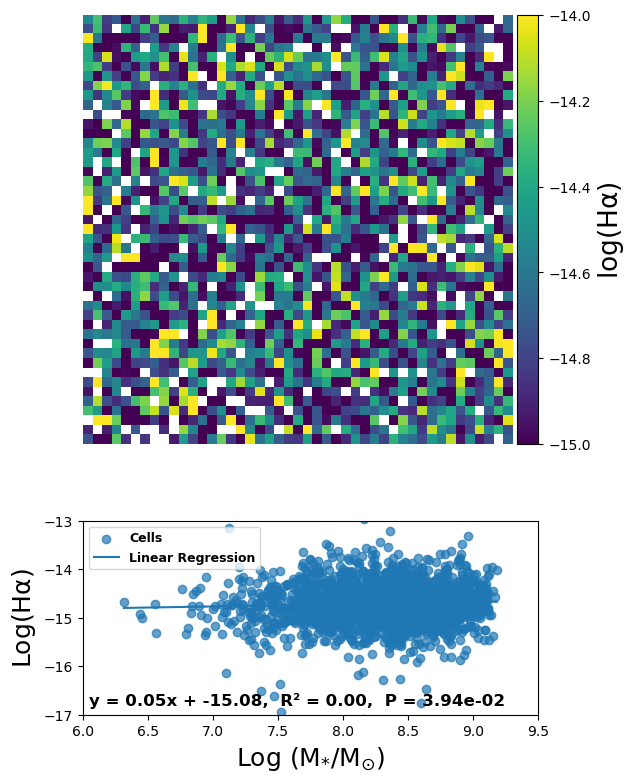

In [107]:
import matplotlib.pyplot as plt
import numpy as np
import matplotlib.gridspec as gridspec
from mpl_toolkits.axes_grid1 import make_axes_locatable

fig = plt.figure(figsize=(6.3, 8.4))  # Increase figure size for larger plot
gs = gridspec.GridSpec(2, 1, height_ratios=[2.7, 1])  # Give more space to the scatter plot (ax1)

# Upper plot (ax0)
ax0 = fig.add_subplot(gs[0, 0])
only_obsha = (Ha > 0)
ha = np.log10(Ha[only_obsha])
hae = 0.434 * (Hae[only_obsha] / Ha[only_obsha])

massajab = massinja[only_obsha]
xha, yha = x[only_obsha], y[only_obsha]

med_b = np.zeros_like(med_r)

haa, maa, haae = [], [], []
for i in range(msz0):
    for j in range(msz1):
        unja = (xha == i) & (yha == j)
        med_b[i, j] = np.nanmedian(ha[unja])
        
        if len(ha[unja]) > 0:
            haa.append(ha[unja].flatten())
            haae.append(hae[unja].flatten())
            maa.append(massajab[unja].flatten())

im = ax0.imshow(med_b, vmin=-15, vmax=-14, origin='lower')
ax0.axis('off')
divider = make_axes_locatable(ax0)
cax = divider.append_axes("right", size="5%", pad=0.05)
cbar = plt.colorbar(im, cax=cax)
cbar.set_label('$\mathrm{log(H\\alpha)}$', fontsize=19)

# Lower plot (ax1) - Scatter plot
ax1 = fig.add_subplot(gs[1, 0])
#maaflat = [item for sublist in maa for item in sublist]
#haaflat = [item for sublist in haa for item in sublist]
#haaeflat = [item for sublist in haae for item in sublist]

# Adjust scatter plot properties for better visibility
#ax1.errorbar(maaflat, haaflat, yerr=haaeflat, fmt='x', color='k', capsize=3, alpha=0.33, label='galaxies')

xx = med_r.flatten()
yy = med_b.flatten()
p_value_hahb = perform_regression_and_plot(ax1, xx, yy, '$\mathrm{Log\ (M_{*} / M_{\odot}})$', '$\mathrm{H\\alpha / H\\beta}$', y_range=(2.5, 8))
plt.legend(loc=2, prop={'size': 9, 'weight': 'bold'})

# Set labels and limits
ax1.set_xlabel('$\mathrm{Log\ (M_{*} / M_{\odot}})$', fontsize=18)
ax1.set_ylabel('$\mathrm{Log(H\\alpha)}$', fontsize=18)
ax1.set_xlim([6, 9.5])
ax1.set_ylim([-17, -13])
plt.tight_layout()

# Save the larger figure
#plt.savefig('plots/Haz1.png', dpi=300)


/var/folders/5z/mxcl46zj3p76_rgxd645pmzr0000gn/T/ipykernel_85968/4195460251.py:6: RuntimeWarning: invalid value encountered in divide
  only_obshb = (Hb > limline) & (Ha > limline) & ((Ha / Hb) > 2.6) & ((Ha / Hb) < 10)
/var/folders/5z/mxcl46zj3p76_rgxd645pmzr0000gn/T/ipykernel_85968/4195460251.py:22: RuntimeWarning: Mean of empty slice
  med_b[i, j] = np.nanmean(hahb[unja])
/var/folders/5z/mxcl46zj3p76_rgxd645pmzr0000gn/T/ipykernel_85968/4195460251.py:48: RuntimeWarning: invalid value encountered in divide
  onlyobsOH = (Hb > limline) & (OIII > limline) & (np.log10(OIII / Hb) > -0.25) & (np.log10(OIII / Hb) < 1)
/var/folders/5z/mxcl46zj3p76_rgxd645pmzr0000gn/T/ipykernel_85968/4195460251.py:48: RuntimeWarning: invalid value encountered in log10
  onlyobsOH = (Hb > limline) & (OIII > limline) & (np.log10(OIII / Hb) > -0.25) & (np.log10(OIII / Hb) < 1)
/var/folders/5z/mxcl46zj3p76_rgxd645pmzr0000gn/T/ipykernel_85968/4195460251.py:49: RuntimeWarning: invalid value encountered in divide
  

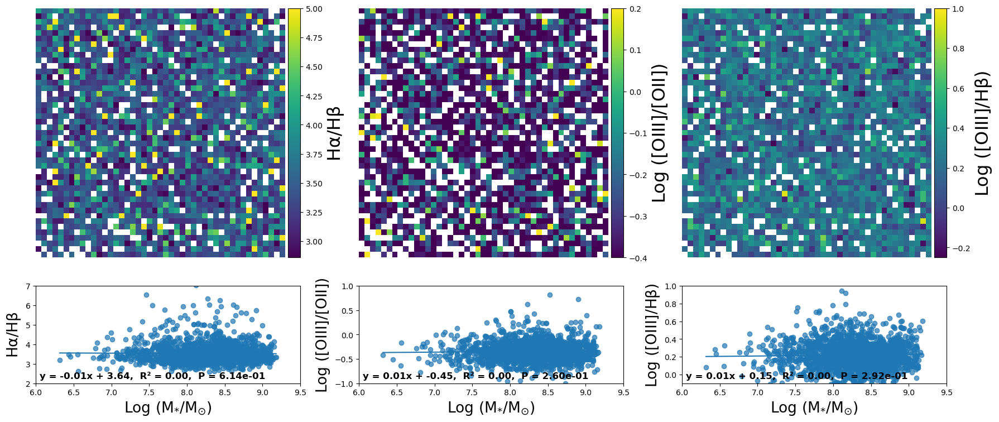

In [115]:
# Create the figure and grid
fig = plt.figure(figsize=(18, 8))
gs = gridspec.GridSpec(2, 3, height_ratios=[3, 1])

# Apply filters to the data
only_obshb = (Hb > limline) & (Ha > limline) & ((Ha / Hb) > 2.6) & ((Ha / Hb) < 10)

# Plot Halpha/Hbeta
ax0 = fig.add_subplot(gs[0, 0])
hahb = Ha[only_obshb] / Hb[only_obshb]
xhahb, yhahb = x[only_obshb], y[only_obshb]

#plt.title('$\mathrm{H\\alpha / H\\beta}$', fontsize = 20)

massajab = massinja[only_obshb]
haa,maa = [],[]

med_b = np.zeros_like(med_r)
for i in range(msz0):
    for j in range(msz1):
        unja = (xhahb == i) & (yhahb == j)
        med_b[i, j] = np.nanmean(hahb[unja])
        if len(hahb[unja])>0:
            haa.append(hahb[unja].flatten())
            maa.append(massajab[unja].flatten())
            
im = ax0.imshow(med_b, vmin=2.86, vmax=5, origin='lower')
ax0.axis('off')
divider = make_axes_locatable(ax0)
cax = divider.append_axes("right", size="5%", pad=0.05)
cbar = plt.colorbar(im, cax=cax)
cbar.set_label('$\mathrm{H\\alpha / H\\beta}$', fontsize=23)

# Scatter plot and regression fit for Halpha/Hbeta
ax5 = fig.add_subplot(gs[1, 0])
#maaflat = [item for sublist in maa for item in sublist]
#haaflat = [item for sublist in haa for item in sublist]
#ax5.scatter(maaflat,haaflat,marker='x', alpha=0.5,color='k',label='galaxies')

xx = med_r.flatten()
yy = med_b.flatten()
p_value_hahb = perform_regression_and_plot(ax5, xx, yy, '$\mathrm{Log\ (M_{*} / M_{\odot}})$', '$\mathrm{H\\alpha / H\\beta}$',y_range=(2.5,7))
ax5.set_xlim([6,9.5])
ax5.set_ylim([2,7])
ax5.set_xlabel('$\mathrm{Log\ (M_{*} / M_{\odot}})$', fontsize = 19)
ax5.set_ylabel('$\mathrm{H\\alpha / H\\beta}$', fontsize = 19)

onlyobsOH = (Hb > limline) & (OIII > limline) & (np.log10(OIII / Hb) > -0.25) & (np.log10(OIII / Hb) < 1)
only_obsO = (OII > limline) & (OIII > limline) & (np.log10(OIII / OII) > -1) & (np.log10(OIII / OII) < 1)

# Plot Log([OIII] / [OII])
ax1 = fig.add_subplot(gs[0, 1])
oiiioii = np.log10(OIII[only_obsO] / OII[only_obsO])
xoiiioii, yoiiioii = x[only_obsO], y[only_obsO]

#plt.title('$\mathrm{Log\ ([OIII] / [OII])}$', fontsize = 20)
    
massajab = massinja[only_obsO]
haa,maa = [],[]

med_b = np.zeros_like(med_r)
for i in range(msz0):
    for j in range(msz1):
        unja = (xoiiioii == i) & (yoiiioii == j)
        med_b[i, j] = np.nanmean(oiiioii[unja])
        if len(oiiioii[unja])>0:
            haa.append(oiiioii[unja].flatten())
            maa.append(massajab[unja].flatten())
            
im = ax1.imshow(med_b, vmin=-0.4, vmax=0.2, origin='lower')
ax1.axis('off')
divider = make_axes_locatable(ax1)
cax = divider.append_axes("right", size="5%", pad=0.05)
cbar = plt.colorbar(im, cax=cax)
cbar.set_label('$\mathrm{Log\ ([OIII] / [OII])}$', fontsize=23)

# Scatter plot and regression fit for Log([OIII] / [OII])
ax3 = fig.add_subplot(gs[1, 1])
#maaflat = [item for sublist in maa for item in sublist]
#haaflat = [item for sublist in haa for item in sublist]
#ax3.scatter(maaflat,haaflat,marker='x', alpha=0.5,color='k',label='galaxies')

xx = med_r.flatten()
yy = med_b.flatten()
p_value_oiiioii = perform_regression_and_plot(ax3, xx, yy, '$\mathrm{Log\ (M_{*} / M_{\odot}})$', '$\mathrm{Log\ ([OIII] / [OII])}$')
ax3.set_xlim([6,9.5])
ax3.set_ylim([-1,1])
ax3.set_xlabel('$\mathrm{Log\ (M_{*} / M_{\odot}})$', fontsize = 19)
ax3.set_ylabel('$\mathrm{Log\ ([OIII] / [OII])}$', fontsize = 19)
# Plot Log([OIII] / Hb)
ax2 = fig.add_subplot(gs[0, 2])
oiiihb = np.log10(OIII[onlyobsOH] / Hb[onlyobsOH])
xoiiihb, yoiiihb = x[onlyobsOH], y[onlyobsOH]

#plt.title('$\mathrm{Log\ ([OIII]} / \mathrm{H\\beta})$', fontsize = 20)

massajab = massinja[onlyobsOH]
haa,maa = [],[]

med_b = np.zeros_like(med_r)
for i in range(msz0):
    for j in range(msz1):
        unja = (xoiiihb == i) & (yoiiihb == j)
        med_b[i, j] = np.nanmean(oiiihb[unja])
        if len(oiiihb[unja])>0:
            haa.append(oiiihb[unja].flatten())
            maa.append(massajab[unja].flatten())
            
im = ax2.imshow(med_b, vmin=-0.25, vmax=1, origin='lower')
ax2.axis('off')
divider = make_axes_locatable(ax2)
cax = divider.append_axes("right", size="5%", pad=0.05)
cbar = plt.colorbar(im, cax=cax)
cbar.set_label('$\mathrm{Log\ ([OIII]} / \mathrm{H\\beta})$', fontsize=23)


# Scatter plot and regression fit for Log([OIII] / Hb)
ax4 = fig.add_subplot(gs[1, 2])
#maaflat = [item for sublist in maa for item in sublist]
#haaflat = [item for sublist in haa for item in sublist]
#ax4.scatter(maaflat,haaflat,marker='x', alpha=0.5,color='k',label='galaxies')
#plt.title('$\mathrm{Log\ ([OIII] / \mathrm{H\\beta})}$',fontsize = 20)

xx = med_r.flatten()
yy = med_b.flatten()
p_value_oiiihb = perform_regression_and_plot(ax4, xx, yy, '$\mathrm{Log\ (M_{*} / M_{\odot}})$', '$\mathrm{Log\ ([OIII] / \mathrm{H\\beta})}$')
ax4.set_xlim([6,9.5])
ax4.set_ylim([-0.1,1])
ax4.set_xlabel('$\mathrm{Log\ (M_{*} / M_{\odot}})$', fontsize = 19)
ax4.set_ylabel('$\mathrm{Log\ ([OIII] / \mathrm{H\\beta})}$', fontsize = 19)

plt.tight_layout()
#plt.savefig('plots/lineratioz1.png', dpi=300)